# Statistical Methods in AI — Assignment 1
## Section 1: Automated Essay Scoring (AES) with K-Nearest Neighbours

**Author:** `neel.rajesh`
**Seed:** derived from the SHA-256 of the IIITH username, as specified in the assignment.

This notebook covers:

| Part | Contents |
|---|---|
| 1.1 | Handcrafted statistical feature engineering (`EssayFeatureExtractor`) |
| 1.2 (a) | Train / validation / test split, 80:10:10 (`DataSplitter`) |
| 1.2 (b) | Z-score standardisation fitted on training data only (`ZScoreNormalizer`) |
| 1.2 (c) | Six feature visualisations (`FeatureVisualizer`) |

All computation logic lives in classes; all plotting logic lives in `FeatureVisualizer`,
keeping visualisation and computation strictly separate as required by the guidelines.

## 0. Setup — imports, reproducible seed, plotting helper

In [1]:
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# NOTE ON BANNED LIBRARIES
# The course clarified that the `re` (regular expression) module and the
# `string` module are both disallowed for this assignment, even though the PDF
# only names NLP libraries. Neither is imported anywhere in this notebook: all
# text processing below uses built-in `str` methods only, which are permitted.
# sklearn and scipy are likewise never used - the split, the normalisation, the
# KNN model and every evaluation metric are hand-written.

# --- Reproducible, personalised seed (assignment specification) -------------
USERNAME = "neel.rajesh"
SEED = int(hashlib.sha256(USERNAME.encode()).hexdigest(), 16) % (2 ** 32)
rng = np.random.default_rng(SEED)

print(f"username : {USERNAME}")
print(f"seed     : {SEED}")

# --- Global plotting defaults ---------------------------------------------
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def add_watermark(ax, username=USERNAME):
    """Stamp the author's email username onto a matplotlib Axes.

    Every plot in this submission must carry the username, as required by the
    assignment's submission instructions.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes to annotate.
    username : str
        The email username to display.
    """
    ax.text(
        0.95, 0.95, username,
        ha="right", va="top", transform=ax.transAxes,
        fontsize=9, color="gray", alpha=0.7,
    )

username : neel.rajesh
seed     : 1754202100


## 0.1 Dataset exploration

Initial exploration used to motivate the feature design. Two observations drive
everything that follows:

1. **Mean word count rises steeply with score** (259 words at score 2 &rarr; 764 at score 6),
   so essay *length* is a strong signal.
2. **Score 1 breaks the monotonic trend** — score-1 essays are *longer* and use a *higher*
   proportion of long words than score-2 essays. Length alone therefore cannot separate the
   bottom two grades, which motivates the length-normalised style features added in 1.1.

In [2]:
df = pd.read_csv('essays.csv')
df.shape
df.head()
df['score'].value_counts().sort_index()
df['word_count'] = df['full_text'].str.split().str.len()
df['long_words'] = df['full_text'].apply(lambda t: len([w for w in t.split() if len(w) > 7]))
df['short_words'] = df['full_text'].apply(lambda t: len([w for w in t.split() if len(w) < 4]))
df['long_word_ratio'] = df['long_words'] / df['word_count']
df['short_word_ratio'] = df['short_words'] / df['word_count']
df.groupby('score').agg(
    no_essays=('essay_id', 'count'),
    mean_words=('word_count', 'mean'),
    std_words=('word_count', 'std'),
    mean_long_ratio=('long_word_ratio', 'mean'),
    mean_short_ratio=('short_word_ratio', 'mean'),
).round(3)

,no_essays,mean_words,std_words,mean_long_ratio,mean_short_ratio
score,,,,,
1,1252,268.400,116.592,0.125,0.413
2,4723,259.020,124.969,0.120,0.411
3,6280,351.038,104.372,0.129,0.401
4,3926,471.107,108.236,0.140,0.394
5,970,624.232,134.456,0.155,0.386
6,156,764.378,160.215,0.174,0.379


In [3]:
# Reload a clean copy: the exploration cell above added scratch columns that are
# not part of the modelling pipeline.
df = pd.read_csv("essays.csv")
print("shape          :", df.shape)
print("columns        :", list(df.columns))
print("missing values :", df.isna().sum().sum())
print()
print("Class balance (note the severe imbalance — score 6 is only 0.9% of the data):")
counts = df["score"].value_counts().sort_index()
print(pd.DataFrame({"n_essays": counts, "share_%": (counts / len(df) * 100).round(2)}))

shape          : (17307, 3)
columns        : ['essay_id', 'full_text', 'score']
missing values : 0

Class balance (note the severe imbalance — score 6 is only 0.9% of the data):
       n_essays  share_%
score                   
1          1252     7.23
2          4723    27.29
3          6280    36.29
4          3926    22.68
5           970     5.60
6           156     0.90


### Choosing the short / medium / long thresholds from the data

Rather than guessing, the thresholds were read off the empirical quantiles of a
seeded 3 000-essay sample:

| Quantity | 25th pct | 50th | 75th | 90th |
|---|---|---|---|---|
| Word length (characters) | 3 | 4 | 6 | 8 |
| Sentence length (words)  | 12 | 17 | 23 | 31 |

This gives the cut-points used throughout:

* **Short word** &le; 3 characters (bottom quartile) — function words: *the, of, is, and*.
* **Medium word** 4–7 characters.
* **Long word** &ge; 8 characters (top decile) — the vocabulary-load tail.
* **Short sentence** &le; 12 words (bottom quartile).
* **Medium sentence** 13–22 words.
* **Long sentence** &ge; 23 words (top quartile).

Because they are quantile-based, the same code would produce sensible cut-points on a
different corpus, and each threshold has a concrete justification.

## 1.1 Feature Engineering

### Design principles

**No NLP libraries are used.** Every feature is computed from raw characters with
built-in string operations and `re` (a general-purpose regular-expression module,
not a linguistic tool).

**Text cleaning.** The raw essays contain double-encoded non-breaking spaces
(`Â\xa0`) which would otherwise fuse adjacent words into one token, and a small
number of anonymisation placeholders (`PROPER_NAME`, `OTHER_PII`) which are
stripped so they do not register as implausibly long words. The corpus contains
**no newline characters**, so paragraph-level features are not computable here.

### Two families of features

The features split deliberately into two groups:

* **Volume features** (raw counts) — these grow with essay length. They capture *how much*
  a candidate wrote, which the exploration showed is strongly score-related.
* **Style features** (rates, ratios and averages) — these are length-normalised, so they
  capture *how* a candidate writes independently of volume. These are what distinguish a
  short but sophisticated essay from a long but repetitive one, and they are the features
  that can separate score 1 from score 2, where raw length fails.

### Feature dictionary

| # | Feature | Family | Motivation / interpretation |
|---|---|---|---|
| 1 | `num_words` | Volume | Total words. Fluency and stamina; the single strongest raw signal. |
| 2 | `num_sentences` | Volume | Total sentences. Proxy for how much the writer developed the argument. |
| 3 | `num_short_words` | Volume | Words &le; 3 chars. Function-word load. |
| 4 | `num_medium_words` | Volume | Words 4–7 chars. Bulk of ordinary vocabulary. |
| 5 | `num_long_words` | Volume | Words &ge; 8 chars. Advanced-vocabulary count. |
| 6 | `num_short_sentences` | Volume | Sentences &le; 12 words. Simple/choppy constructions. |
| 7 | `num_medium_sentences` | Volume | Sentences 13–22 words. |
| 8 | `num_long_sentences` | Volume | Sentences &ge; 23 words. Complex, subordinated constructions. |
| 9 | `avg_word_length` | Style | Mean characters per word. Classic readability proxy for vocabulary difficulty. |
| 10 | `avg_sentence_length` | Style | Mean words per sentence. Syntactic complexity. |
| 11 | `sentence_length_std` | Style | Spread of sentence lengths. **Sentence variety** — strong writers mix short and long sentences; weak writers repeat one rhythm. |
| 12 | `long_word_ratio` | Style | Long words &divide; total words. Vocabulary sophistication, independent of length. |
| 13 | `short_word_ratio` | Style | Short words &divide; total words. High values indicate simple, function-word-heavy prose. |
| 14 | `type_token_ratio` | Style | Unique words &divide; total words. **Lexical diversity** — penalises repetitive vocabulary. Note it falls naturally with length, so it partly encodes length too. |
| 15 | `commas_per_sentence` | Style | Comma use per sentence. Proxy for clause-level complexity (lists, subordination). |
| 16 | `punctuation_diversity` | Style | Count of *distinct* punctuation marks used. A writer who deploys `;`, `:` and quotation marks demonstrates control that a `.`-and-`,`-only writer does not. Deliberately a diversity count, not a total count, so it does not simply re-measure length. |
| 17 | `capitalised_start_ratio` | Style | Fraction of sentences beginning with a capital. Basic **mechanics/conventions** compliance. |
| 18 | `misspelling_proxy_ratio` | Style | Fraction of words that are structurally implausible — no vowel despite being &ge; 4 letters, or containing a triple repeated letter. A **dictionary-free** spelling-error proxy (no word list or spell-checker is used, so no banned resource is involved). **Measured, found uninformative, and dropped** — see the negative-result section below. |

### A note on dimensionality

KNN sums distance over *every* dimension, so an uninformative feature adds noise to every
comparison — the curse of dimensionality. The set is kept deliberately modest: **18
features are extracted and 17 are retained**, with the 18th dropped on the evidence of the
separation report below rather than kept "just in case". The correlation heat-map in
1.2 (c) is then used to identify which of the survivors are redundant with one another.

In [4]:
class EssayFeatureExtractor:
    """Extract handcrafted statistical features from raw essay text.

    All features are computed directly from characters using **built-in string
    methods only**. The `re` module and the `string` module are both banned for
    this assignment, so tokenisation and sentence splitting are implemented by
    hand rather than with regular expressions. No NLP library, word list,
    spell-checker or pretrained model is used either.

    The short/medium/long thresholds are constructor arguments rather than
    hard-coded literals, so they are explicit, documented design decisions and
    can be re-tuned on a different corpus.

    Parameters
    ----------
    short_word_max : int
        Maximum character length for a word to count as "short" (inclusive).
    long_word_min : int
        Minimum character length for a word to count as "long" (inclusive).
    short_sentence_max : int
        Maximum word count for a sentence to count as "short" (inclusive).
    long_sentence_min : int
        Minimum word count for a sentence to count as "long" (inclusive).
    """

    #: Punctuation marks tracked for the diversity feature.
    PUNCTUATION = set(".,;:!?'\"()-")

    #: Anonymisation placeholders present in this corpus.
    PLACEHOLDERS = ("PROPER_NAME", "OTHER_PII", "GENERIC_NAME", "LOCATION_NAME")

    VOWELS = set("aeiouy")

    #: Straight and typographic apostrophes, kept inside words ("don't").
    APOSTROPHES = "'‘’"

    #: Characters that terminate a sentence.
    SENTENCE_ENDINGS = ".!?"

    def __init__(self, short_word_max=3, long_word_min=8,
                 short_sentence_max=12, long_sentence_min=23):
        """Initialise the feature extractor with quantile-derived thresholds."""
        self.short_word_max = short_word_max
        self.long_word_min = long_word_min
        self.short_sentence_max = short_sentence_max
        self.long_sentence_min = long_sentence_min

    # ------------------------------------------------------------------
    # Internal text-processing helpers (built-in str methods only)
    # ------------------------------------------------------------------
    def _clean_text(self, essay):
        """Normalise raw essay text before tokenisation.

        Repairs the double-encoded non-breaking spaces present in this corpus
        (the sequence "\xc2\xa0", which would otherwise fuse adjacent words into a
        single token) and removes anonymisation placeholders so they are not
        mistaken for genuine long words.

        The final `" ".join(text.split())` collapses every run of whitespace to
        a single space: `str.split()` with no argument splits on arbitrary
        whitespace and discards empty pieces, which is the plain-string
        equivalent of a regex whitespace substitution.

        Parameters
        ----------
        essay : str
            Raw essay text.

        Returns
        -------
        str
            Cleaned text.
        """
        text = str(essay)
        text = text.replace("\xc2\xa0", " ").replace("\xa0", " ").replace("\xc2", " ")
        for placeholder in self.PLACEHOLDERS:
            text = text.replace(placeholder, " ")
        return " ".join(text.split())

    def _tokenize_words(self, text):
        """Split text into alphabetic word tokens, without regular expressions.

        Every character that is not a letter and not an apostrophe is replaced
        by a space; splitting the result on whitespace then yields the words.
        This handles the corpus's frequent missing spaces after punctuation
        ("europe...and", "cars,and"), which a simple `split()` plus edge
        stripping would return as single oversized tokens and which would badly
        inflate the long-word counts. Digits are dropped along with punctuation,
        since numerals say nothing about vocabulary.

        Parameters
        ----------
        text : str
            Cleaned text.

        Returns
        -------
        list of str
            Word tokens (original capitalisation preserved).
        """
        spaced = "".join(
            ch if (ch.isalpha() or ch in self.APOSTROPHES) else " "
            for ch in text
        )
        tokens = []
        for raw in spaced.split():
            token = raw.strip(self.APOSTROPHES)
            if token:
                tokens.append(token)
        return tokens

    def _split_sentences(self, text):
        """Split text into sentences on terminal punctuation, without regex.

        `!` and `?` are rewritten to `.` so that a single `str.split(".")`
        handles all three terminators. Empty fragments - produced by runs such
        as "..." or by trailing punctuation - are discarded, which reproduces
        the behaviour of splitting on a run of terminators.

        Parameters
        ----------
        text : str
            Cleaned text.

        Returns
        -------
        list of str
            Non-empty sentence strings.
        """
        normalised = text
        for ending in self.SENTENCE_ENDINGS[1:]:      # "!" and "?"
            normalised = normalised.replace(ending, ".")
        return [part.strip() for part in normalised.split(".") if part.strip()]

    def _looks_misspelled(self, word):
        """Heuristically flag a word as structurally implausible.

        A dictionary-free proxy for spelling errors: a token is flagged when it
        either (a) has four or more letters but contains no vowel, or
        (b) contains the same letter three times consecutively ("willl",
        "classrooom"). Both patterns are rare in correctly spelled English but
        common in typing errors. The triple-letter test is a plain loop rather
        than a backreference regex, since `re` is banned.

        All-uppercase tokens are exempt, since acronyms (NASA, BMW, FACS) are
        legitimately vowel-free and would otherwise dominate the count.

        Parameters
        ----------
        word : str
            A single word token, original capitalisation preserved.

        Returns
        -------
        bool
            True if the token looks misspelled.
        """
        if word.isupper():
            return False
        letters = "".join(ch for ch in word.lower() if ch.isalpha())
        if len(letters) >= 4 and not (set(letters) & self.VOWELS):
            return True
        for i in range(len(letters) - 2):
            if letters[i] == letters[i + 1] == letters[i + 2]:
                return True
        return False

    # ------------------------------------------------------------------
    # Public API
    # ------------------------------------------------------------------
    def extract_features(self, essay: str) -> dict:
        """Extract all handcrafted features from a single essay.

        Parameters
        ----------
        essay : str
            Raw essay text.

        Returns
        -------
        dict
            Mapping of feature name to numeric value. Keys are identical for
            every essay, so the results stack directly into a DataFrame.
        """
        text = self._clean_text(essay)
        words = self._tokenize_words(text)
        sentences = self._split_sentences(text)

        word_lengths = [len(w) for w in words]
        sentence_lengths = [len(self._tokenize_words(s)) for s in sentences]

        n_words = len(words)
        n_sentences = len(sentences)

        # Guard against division by zero for degenerate essays. (This corpus has
        # a minimum of 142 words, so these guards never actually trigger here,
        # but they make the extractor safe to reuse.)
        safe_words = max(n_words, 1)
        safe_sentences = max(n_sentences, 1)

        # --- Volume features: word-length bands ---------------------------
        n_short_words = sum(1 for L in word_lengths if L <= self.short_word_max)
        n_long_words = sum(1 for L in word_lengths if L >= self.long_word_min)
        n_medium_words = n_words - n_short_words - n_long_words

        # --- Volume features: sentence-length bands -----------------------
        n_short_sentences = sum(
            1 for L in sentence_lengths if L <= self.short_sentence_max)
        n_long_sentences = sum(
            1 for L in sentence_lengths if L >= self.long_sentence_min)
        n_medium_sentences = n_sentences - n_short_sentences - n_long_sentences

        # --- Style features ------------------------------------------------
        lowered = [w.lower() for w in words]
        n_unique = len(set(lowered))
        n_misspelled = sum(1 for w in words if self._looks_misspelled(w))
        n_capitalised_starts = sum(1 for s in sentences if s[:1].isupper())
        punctuation_used = {ch for ch in text if ch in self.PUNCTUATION}

        return {
            # Volume
            "num_words": float(n_words),
            "num_sentences": float(n_sentences),
            "num_short_words": float(n_short_words),
            "num_medium_words": float(n_medium_words),
            "num_long_words": float(n_long_words),
            "num_short_sentences": float(n_short_sentences),
            "num_medium_sentences": float(n_medium_sentences),
            "num_long_sentences": float(n_long_sentences),
            # Style
            "avg_word_length": float(np.mean(word_lengths)) if words else 0.0,
            "avg_sentence_length": n_words / safe_sentences,
            "sentence_length_std": float(np.std(sentence_lengths)) if sentences else 0.0,
            "long_word_ratio": n_long_words / safe_words,
            "short_word_ratio": n_short_words / safe_words,
            "type_token_ratio": n_unique / safe_words,
            "commas_per_sentence": text.count(",") / safe_sentences,
            "punctuation_diversity": float(len(punctuation_used)),
            "capitalised_start_ratio": n_capitalised_starts / safe_sentences,
            "misspelling_proxy_ratio": n_misspelled / safe_words,
        }

    def extract_dataset_features(self, essays) -> pd.DataFrame:
        """Extract features for every essay in a collection.

        Parameters
        ----------
        essays : iterable of str
            Essay texts (e.g. a pandas Series).

        Returns
        -------
        pandas.DataFrame
            One row per essay, one column per feature, in input order.
        """
        rows = [self.extract_features(essay) for essay in essays]
        return pd.DataFrame(rows, index=getattr(essays, "index", None))


print("EssayFeatureExtractor defined (no `re`, no `string` module).")

EssayFeatureExtractor defined (no `re`, no `string` module).


### Sanity check on a single hand-written essay

In [5]:
# Verify the extractor on a tiny, hand-checkable example before running it on 17k essays.
demo = ("The cat sat. It was extraordinarily fat, and lazy; nevertheless "
        "it purrrred loudly when the sun rose over the neighbourhood rooftops.")

extractor = EssayFeatureExtractor()
demo_features = extractor.extract_features(demo)

for name, value in demo_features.items():
    print(f"{name:>28} : {value:.4f}")

                   num_words : 21.0000
               num_sentences : 2.0000
             num_short_words : 11.0000
            num_medium_words : 5.0000
              num_long_words : 5.0000
         num_short_sentences : 1.0000
        num_medium_sentences : 1.0000
          num_long_sentences : 0.0000
             avg_word_length : 5.1905
         avg_sentence_length : 10.5000
         sentence_length_std : 7.5000
             long_word_ratio : 0.2381
            short_word_ratio : 0.5238
            type_token_ratio : 0.8571
         commas_per_sentence : 0.5000
       punctuation_diversity : 3.0000
     capitalised_start_ratio : 1.0000
     misspelling_proxy_ratio : 0.0476


In [6]:
# Extract features for the full corpus (takes roughly half a minute).
features_df = extractor.extract_dataset_features(df["full_text"])
labels = df["score"].to_numpy()

print("feature matrix shape :", features_df.shape)
print("any NaN / inf        :",
      features_df.isna().any().any() or np.isinf(features_df.to_numpy()).any())
features_df.head()

feature matrix shape : (17307, 18)
any NaN / inf        : False


,num_words,num_sentences,num_short_words,num_medium_words,num_long_words,num_short_sentences,num_medium_sentences,num_long_sentences,avg_word_length,avg_sentence_length,sentence_length_std,long_word_ratio,short_word_ratio,type_token_ratio,commas_per_sentence,punctuation_diversity,capitalised_start_ratio,misspelling_proxy_ratio
0,498.0,13.0,212.0,246.0,40.0,2.0,2.0,9.0,4.244980,38.307692,31.682037,0.080321,0.425703,0.445783,1.076923,4.0,1.000000,0.0
1,332.0,21.0,153.0,152.0,27.0,9.0,8.0,4.0,3.903614,15.809524,10.219585,0.081325,0.460843,0.439759,0.285714,6.0,0.952381,0.0
2,551.0,24.0,232.0,254.0,65.0,3.0,8.0,13.0,4.470054,22.958333,8.710526,0.117967,0.421053,0.413793,0.666667,5.0,1.000000,0.0
3,447.0,21.0,169.0,201.0,77.0,2.0,10.0,9.0,4.865772,21.285714,8.783875,0.172260,0.378076,0.483221,0.904762,9.0,0.904762,0.0
4,374.0,16.0,165.0,148.0,61.0,4.0,6.0,6.0,4.700535,23.375000,16.541142,0.163102,0.441176,0.371658,0.812500,7.0,0.937500,0.0


In [7]:
features_df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
num_words,17307.0,366.956,149.958,150.000,252.000,343.000,451.000,1656.000
num_sentences,17307.0,19.878,8.835,1.000,13.000,19.000,25.000,135.000
num_short_words,17307.0,149.730,62.076,45.000,103.000,139.000,184.000,792.000
num_medium_words,17307.0,175.387,71.706,51.000,121.000,164.000,216.000,840.000
num_long_words,17307.0,41.838,24.852,1.000,24.000,37.000,54.000,270.000
num_short_sentences,17307.0,5.999,5.243,0.000,2.000,5.000,8.000,119.000
num_medium_sentences,17307.0,8.478,4.779,0.000,5.000,8.000,11.000,36.000
num_long_sentences,17307.0,5.401,3.618,0.000,3.000,5.000,7.000,48.000
avg_word_length,17307.0,4.431,0.293,3.438,4.227,4.430,4.635,5.667
avg_sentence_length,17307.0,20.244,13.199,5.354,15.667,18.429,22.000,713.000


### Do the features actually separate the scores?

The table below reports each feature's mean per score, plus a **separation ratio**:
the standard deviation of the six per-score means divided by the average within-score
standard deviation. Larger values indicate a feature whose between-score variation is
large relative to its within-score noise — i.e. a feature that genuinely discriminates.

In [8]:
def feature_separation_report(features, y):
    """Summarise how well each feature separates the score classes.

    For each feature, computes the mean within each score class and a
    separation ratio: std-of-class-means divided by mean-within-class-std.

    Parameters
    ----------
    features : pandas.DataFrame
        Feature matrix.
    y : array-like
        Class labels (essay scores).

    Returns
    -------
    pandas.DataFrame
        Per-score means plus a ``separation`` column, sorted descending.
    """
    grouped = features.groupby(y)
    class_means = grouped.mean()
    between = class_means.std(axis=0)
    within = grouped.std().mean(axis=0)
    report = class_means.T.copy()
    report.columns = [f"score_{c}" for c in class_means.index]
    report["separation"] = (between / within.replace(0, np.nan)).values
    return report.sort_values("separation", ascending=False).round(3)


separation = feature_separation_report(features_df, labels)
separation

,score_1,score_2,score_3,score_4,score_5,score_6,separation
num_words,265.621,257.937,352.552,473.542,625.962,767.756,1.767
num_medium_words,126.161,123.923,169.508,225.860,294.639,353.545,1.655
num_long_words,29.183,26.044,38.461,56.811,84.242,117.032,1.624
num_short_words,110.277,107.970,144.584,190.871,247.080,297.179,1.470
num_long_sentences,3.835,3.635,4.944,7.121,10.556,14.532,1.275
num_sentences,14.018,14.163,19.643,25.427,31.660,36.551,1.206
type_token_ratio,0.539,0.520,0.470,0.434,0.407,0.388,1.000
num_medium_sentences,5.343,5.760,8.436,11.293,13.711,14.244,0.859
punctuation_diversity,4.056,4.212,4.853,5.563,6.321,6.827,0.677
long_word_ratio,0.109,0.101,0.110,0.121,0.136,0.153,0.499


### A negative result: dropping `misspelling_proxy_ratio`

The dictionary-free misspelling proxy was an attractive idea — spelling accuracy is
obviously score-relevant — but measurement shows it does not work on this corpus, and it
is dropped rather than quietly retained.

**Why it fails.** The heuristic fires on roughly **0.03% of tokens** (a few hundred out of
1.4 million). It does catch genuine errors (`thst`, `willl`, `reallly`, `driverlesss`,
`classrooom`), but a rate that low cannot separate classes: its separation ratio is
**0.04**, an order of magnitude below every other feature. The great majority of real
misspellings in these essays (`accidet`, `probaly`, `alot`, `dont`) are perfectly
plausible letter sequences that only a dictionary could reject — and a word list is
exactly the kind of external resource the question rules out.

**What is kept instead.** `capitalised_start_ratio` turns out to be the mechanics feature
that does work: it is markedly lower for score-1 essays than for any other grade, which is
a real, measurable convention failure.

Reporting and removing an unsuccessful feature is deliberate: carrying a near-constant
column into a distance-based model adds a noise dimension for no information gain.

In [9]:
# Drop the feature that measurement showed to be uninformative.
DROPPED_FEATURES = ["misspelling_proxy_ratio"]
MODEL_FEATURES = [c for c in features_df.columns if c not in DROPPED_FEATURES]

print(f"features extracted : {features_df.shape[1]}")
print(f"features dropped   : {DROPPED_FEATURES}")
print(f"features modelled  : {len(MODEL_FEATURES)}")

features extracted : 18
features dropped   : ['misspelling_proxy_ratio']
features modelled  : 17


## 1.2 Dataset Preprocessing

### 1.2 (a) Train–Validation–Test Split [80 : 10 : 10]

The split is **stratified** by score. This is a deliberate choice: score 6 accounts for
only 156 of 17 307 essays (0.9%), so an unstratified random split could easily leave the
validation or test set with a badly unrepresentative number of them. Stratifying
guarantees each split preserves the overall class proportions, which makes the validation
scores in 1.3 and the test metrics in 1.4 comparable and stable.

All randomness flows from the single seeded `numpy.random.Generator`, so the split is
exactly reproducible.

In [10]:
class DataSplitter:
    """Split a dataset into train / validation / test partitions.

    Supports stratified splitting, which preserves each class's proportion
    within every partition — important here because the score distribution is
    severely imbalanced.

    Parameters
    ----------
    train_ratio, val_ratio, test_ratio : float
        Partition proportions; must sum to 1.
    seed : int
        Seed for the internal random generator, ensuring reproducibility.
    """

    def __init__(self, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1, seed=SEED):
        """Initialise the splitter and validate the requested ratios."""
        total = train_ratio + val_ratio + test_ratio
        if not np.isclose(total, 1.0):
            raise ValueError(f"ratios must sum to 1, got {total}")
        self.train_ratio = train_ratio
        self.val_ratio = val_ratio
        self.test_ratio = test_ratio
        self.seed = seed

    def _split_indices(self, indices, rng):
        """Shuffle one block of indices and cut it into three partitions.

        Parameters
        ----------
        indices : numpy.ndarray
            Positional indices to partition.
        rng : numpy.random.Generator
            Seeded generator supplying the shuffle.

        Returns
        -------
        tuple of numpy.ndarray
            (train, validation, test) index arrays.
        """
        shuffled = rng.permutation(indices)
        n = len(shuffled)
        n_train = int(round(self.train_ratio * n))
        n_val = int(round(self.val_ratio * n))
        return (shuffled[:n_train],
                shuffled[n_train:n_train + n_val],
                shuffled[n_train + n_val:])

    def split(self, y, stratify=True):
        """Produce train / validation / test positional indices.

        Parameters
        ----------
        y : array-like
            Class labels, used for stratification.
        stratify : bool
            If True, split within each class so proportions are preserved.

        Returns
        -------
        dict
            Keys ``"train"``, ``"val"``, ``"test"`` mapping to index arrays.
        """
        rng = np.random.default_rng(self.seed)
        y = np.asarray(y)

        if not stratify:
            train, val, test = self._split_indices(np.arange(len(y)), rng)
        else:
            train_parts, val_parts, test_parts = [], [], []
            for cls in np.unique(y):
                cls_idx = np.flatnonzero(y == cls)
                tr, va, te = self._split_indices(cls_idx, rng)
                train_parts.append(tr)
                val_parts.append(va)
                test_parts.append(te)
            train = np.concatenate(train_parts)
            val = np.concatenate(val_parts)
            test = np.concatenate(test_parts)

        # Shuffle again so the partitions are not ordered by class.
        return {"train": rng.permutation(train),
                "val": rng.permutation(val),
                "test": rng.permutation(test)}


splitter = DataSplitter(0.8, 0.1, 0.1, seed=SEED)
idx = splitter.split(labels, stratify=True)

X = features_df[MODEL_FEATURES].to_numpy(dtype=float)
FEATURE_NAMES = list(MODEL_FEATURES)

X_train, y_train = X[idx["train"]], labels[idx["train"]]
X_val,   y_val   = X[idx["val"]],   labels[idx["val"]]
X_test,  y_test  = X[idx["test"]],  labels[idx["test"]]

print("Split sizes (80 : 10 : 10)")
print("-" * 46)
for name, arr in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<12} {len(arr):>6,} samples   ({len(arr) / len(labels) * 100:5.2f}%)")
print("-" * 46)
print(f"{'Total':<12} {len(labels):>6,} samples")

Split sizes (80 : 10 : 10)
----------------------------------------------
Training     13,846 samples   (80.00%)
Validation    1,731 samples   (10.00%)
Test          1,730 samples   (10.00%)
----------------------------------------------
Total        17,307 samples


In [11]:
# Confirm stratification preserved the class proportions in every partition.
proportions = pd.DataFrame({
    "full":  pd.Series(labels).value_counts(normalize=True).sort_index(),
    "train": pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "val":   pd.Series(y_val).value_counts(normalize=True).sort_index(),
    "test":  pd.Series(y_test).value_counts(normalize=True).sort_index(),
}).mul(100).round(2)
proportions.index.name = "score"

counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "val":   pd.Series(y_val).value_counts().sort_index(),
    "test":  pd.Series(y_test).value_counts().sort_index(),
})
counts.index.name = "score"

print("Class share per partition (%):")
print(proportions)
print()
print("Raw counts per partition:")
print(counts)

Class share per partition (%):
        full  train    val   test
score                            
1       7.23   7.24   7.22   7.23
2      27.29  27.29  27.27  27.34
3      36.29  36.28  36.28  36.30
4      22.68  22.69  22.70  22.66
5       5.60   5.60   5.60   5.61
6       0.90   0.90   0.92   0.87

Raw counts per partition:
       train  val  test
score                  
1       1002  125   125
2       3778  472   473
3       5024  628   628
4       3141  393   392
5        776   97    97
6        125   16    15


### 1.2 (b) Feature Normalisation — Z-score standardisation

$$z = \frac{x - \mu}{\sigma}$$

KNN ranks neighbours by distance, and distance is a sum over features. Without
standardisation `num_words` (hundreds) would swamp `long_word_ratio` (between 0 and 1)
entirely — the ratio features would contribute essentially nothing to any distance.
Z-scoring puts every feature on a common scale of "standard deviations from the mean".

**$\mu$ and $\sigma$ are estimated on the training split only**, then applied unchanged
to validation and test. Using statistics computed over the whole dataset would leak
information about the held-out data into the model and inflate the reported performance.

A consequence worth stating: standardisation gives every feature *equal* influence on the
distance, regardless of how informative it is. This is precisely why a weak feature is not
free — it is why the feature set was kept deliberately small.

In [12]:
class ZScoreNormalizer:
    """Standardise features to zero mean and unit variance.

    Follows the fit/transform contract: statistics are learned once from the
    training data (``fit``) and then applied unchanged to any other split
    (``transform``), which prevents information from the validation and test
    sets leaking into the model.

    Attributes
    ----------
    mean_ : numpy.ndarray
        Per-feature training means, available after ``fit``.
    std_ : numpy.ndarray
        Per-feature training standard deviations, available after ``fit``.
    """

    def __init__(self):
        """Initialise an unfitted normaliser."""
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        """Learn per-feature mean and standard deviation from training data.

        Parameters
        ----------
        X : numpy.ndarray
            Training feature matrix of shape (n_samples, n_features).

        Returns
        -------
        ZScoreNormalizer
            self, to allow method chaining.
        """
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        # A zero-variance feature carries no information; guard against
        # division by zero by leaving such a column as all zeros after centring.
        self.std_ = np.where(std == 0, 1.0, std)
        return self

    def transform(self, X):
        """Apply the learned standardisation to a feature matrix.

        Parameters
        ----------
        X : numpy.ndarray
            Feature matrix of shape (n_samples, n_features).

        Returns
        -------
        numpy.ndarray
            Standardised feature matrix.

        Raises
        ------
        RuntimeError
            If called before ``fit``.
        """
        if self.mean_ is None:
            raise RuntimeError("ZScoreNormalizer must be fitted before transform().")
        return (np.asarray(X, dtype=float) - self.mean_) / self.std_

    def fit_transform(self, X):
        """Fit on ``X`` and return the standardised version of ``X``."""
        return self.fit(X).transform(X)


normalizer = ZScoreNormalizer().fit(X_train)          # training data ONLY
X_train_std = normalizer.transform(X_train)
X_val_std   = normalizer.transform(X_val)
X_test_std  = normalizer.transform(X_test)

check = pd.DataFrame({
    "train_mean": X_train_std.mean(axis=0),
    "train_std":  X_train_std.std(axis=0),
    "val_mean":   X_val_std.mean(axis=0),
    "val_std":    X_val_std.std(axis=0),
    "test_mean":  X_test_std.mean(axis=0),
    "test_std":   X_test_std.std(axis=0),
}, index=FEATURE_NAMES).round(3)

print("Training features are exactly standardised (mean 0, std 1).")
print("Validation/test means are near — but not exactly — 0, which is correct:")
print("they were transformed using the TRAINING statistics, not their own.\n")
check

Training features are exactly standardised (mean 0, std 1).
Validation/test means are near — but not exactly — 0, which is correct:
they were transformed using the TRAINING statistics, not their own.



,train_mean,train_std,val_mean,val_std,test_mean,test_std
num_words,0.0,1.0,-0.002,0.971,0.004,0.997
num_sentences,-0.0,1.0,-0.025,0.972,-0.005,0.987
num_short_words,0.0,1.0,-0.004,0.964,-0.002,0.999
num_medium_words,0.0,1.0,-0.010,0.968,0.000,0.990
num_long_words,0.0,1.0,0.026,1.012,0.027,1.023
num_short_sentences,0.0,1.0,-0.032,0.972,-0.018,0.966
num_medium_sentences,0.0,1.0,-0.014,1.009,-0.008,0.982
num_long_sentences,-0.0,1.0,0.004,0.987,0.026,0.995
avg_word_length,-0.0,1.0,0.030,1.007,0.049,0.990
avg_sentence_length,-0.0,1.0,0.065,1.319,-0.002,0.828


### 1.2 (c) Feature Visualisation

Six visualisations, each with a title, axis labels, a legend, and the author's username.
Plotting is confined to the `FeatureVisualizer` class; no computation of features happens
inside it, keeping visualisation and computation logic separate as the guidelines require.

In [13]:
class FeatureVisualizer:
    """Visualisations for the handcrafted essay features.

    Purely presentational: every method receives already-computed arrays and is
    responsible only for drawing. All figures are titled, axis-labelled,
    legended and watermarked with the author's username.

    Parameters
    ----------
    feature_names : list of str
        Column names of the feature matrix.
    username : str
        Username stamped onto every figure.
    """

    def __init__(self, feature_names, username=USERNAME):
        """Store the feature names and watermark text used by every plot."""
        self.feature_names = list(feature_names)
        self.username = username

    def plot_class_distribution(self, y_train, y_val, y_test):
        """Grouped bar chart of score counts across the three partitions.

        Demonstrates both the class imbalance and that stratification preserved
        the score proportions in every split.
        """
        scores = np.arange(1, 7)
        width = 0.27
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for offset, (arr, label) in zip(
            (-width, 0.0, width),
            [(y_train, "Train"), (y_val, "Validation"), (y_test, "Test")],
        ):
            counts = [np.sum(arr == s) for s in scores]
            bars = ax.bar(scores + offset, counts, width, label=label)
            ax.bar_label(bars, fontsize=7, padding=1)
        ax.set_yscale("log")
        ax.set_title(f"Essay score distribution across data partitions — {self.username}")
        ax.set_xlabel("Essay score (human-assigned, 1–6)")
        ax.set_ylabel("Number of essays (log scale)")
        ax.set_xticks(scores)
        ax.legend(title="Partition")
        add_watermark(ax, self.username)
        plt.tight_layout()
        plt.show()

    def plot_feature_histograms(self, X, y, features):
        """Overlaid histograms of selected features by score band.

        Scores are pooled into Low (1–2), Medium (3–4) and High (5–6) bands so
        the comparison stays legible; densities are normalised so the bands are
        comparable despite very different group sizes.
        """
        bands = [("Low (1-2)", (1, 2)), ("Medium (3-4)", (3, 4)), ("High (5-6)", (5, 6))]
        fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
        for ax, feature in zip(axes.ravel(), features):
            col = self.feature_names.index(feature)
            values = X[:, col]
            bins = np.linspace(np.percentile(values, 0.5),
                               np.percentile(values, 99.5), 40)
            for label, band in bands:
                mask = np.isin(y, band)
                ax.hist(values[mask], bins=bins, density=True,
                        alpha=0.55, label=label)
            ax.set_title(feature)
            ax.set_xlabel(feature.replace("_", " "))
            ax.set_ylabel("Density")
            ax.legend(title="Score band", fontsize=8)
            add_watermark(ax, self.username)
        fig.suptitle(
            f"Feature distributions by score band — {self.username}", fontsize=13)
        plt.tight_layout()
        plt.show()

    def plot_feature_boxplots(self, X, y, features):
        """Box plots of selected features against each score.

        Box plots expose the median, inter-quartile range and outliers, making
        it immediately visible whether score groups overlap.
        """
        scores = np.arange(1, 7)
        fig, axes = plt.subplots(1, len(features), figsize=(6 * len(features), 4.6))
        axes = np.atleast_1d(axes)
        for ax, feature in zip(axes, features):
            col = self.feature_names.index(feature)
            data = [X[y == s, col] for s in scores]
            bp = ax.boxplot(data, tick_labels=scores, showfliers=False,
                            patch_artist=True)
            for patch in bp["boxes"]:
                patch.set_facecolor("#8fbcd4")
            ax.plot(scores, [np.mean(d) for d in data], "o-", color="crimson",
                    label="Group mean")
            ax.set_title(f"{feature} by score")
            ax.set_xlabel("Essay score (1–6)")
            ax.set_ylabel(feature.replace("_", " "))
            ax.legend()
            add_watermark(ax, self.username)
        fig.suptitle(f"Feature spread within each score — {self.username}", fontsize=13)
        plt.tight_layout()
        plt.show()

    def plot_correlation_heatmap(self, X):
        """Heat map of the pairwise Pearson correlation between features.

        Used to identify redundant features: highly correlated pairs contribute
        near-duplicate information to the KNN distance.
        """
        corr = np.corrcoef(X, rowvar=False)
        n = len(self.feature_names)
        fig, ax = plt.subplots(figsize=(10.5, 9))
        im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(n))
        ax.set_yticks(range(n))
        ax.set_xticklabels(self.feature_names, rotation=90, fontsize=8)
        ax.set_yticklabels(self.feature_names, fontsize=8)
        for i in range(n):
            for j in range(n):
                ax.text(j, i, f"{corr[i, j]:.1f}", ha="center", va="center",
                        fontsize=5.5,
                        color="white" if abs(corr[i, j]) > 0.6 else "black")
        fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation r")
        ax.set_title(f"Feature correlation matrix (training split) — {self.username}")
        ax.set_xlabel("Feature")
        ax.set_ylabel("Feature")
        ax.grid(False)
        add_watermark(ax, self.username)
        plt.tight_layout()
        plt.show()

    def plot_feature_scatter(self, X, y, feature_x, feature_y, sample=3000, seed=SEED):
        """Scatter plot of two features, coloured by essay score.

        A seeded subsample keeps the plot readable; colour encodes the score so
        class structure (or its absence) in the 2-D projection is visible.
        """
        gen = np.random.default_rng(seed)
        take = gen.choice(len(y), size=min(sample, len(y)), replace=False)
        cx = self.feature_names.index(feature_x)
        cy = self.feature_names.index(feature_y)
        fig, ax = plt.subplots(figsize=(8.5, 6))
        sc = ax.scatter(X[take, cx], X[take, cy], c=y[take], cmap="viridis",
                        s=11, alpha=0.6, label="Essay (subsampled)")
        cbar = fig.colorbar(sc, ax=ax, ticks=range(1, 7), label="Essay score")
        cbar.set_label("Essay score (1–6)")
        ax.set_title(
            f"{feature_x} vs {feature_y}, coloured by score — {self.username}")
        ax.set_xlabel(feature_x.replace("_", " "))
        ax.set_ylabel(feature_y.replace("_", " "))
        ax.legend(loc="upper right")
        add_watermark(ax, self.username)
        plt.tight_layout()
        plt.show()

    def plot_standardised_profiles(self, X_std, y):
        """Mean standardised value of every feature, per score.

        Because the axes are in standard-deviation units, features can be
        compared directly: a line that fans out from score 1 to score 6
        indicates a feature that discriminates between grades.
        """
        scores = np.arange(1, 7)
        fig, ax = plt.subplots(figsize=(12, 6))
        positions = np.arange(len(self.feature_names))
        for s in scores:
            means = X_std[y == s].mean(axis=0)
            ax.plot(positions, means, "o-", label=f"Score {s}", linewidth=1.6,
                    markersize=4)
        ax.axhline(0, color="black", linewidth=0.8, linestyle="--",
                   label="Training mean (z = 0)")
        ax.set_xticks(positions)
        ax.set_xticklabels(self.feature_names, rotation=90, fontsize=8)
        ax.set_title(
            f"Mean standardised feature value by essay score — {self.username}")
        ax.set_xlabel("Feature")
        ax.set_ylabel("Mean z-score (training statistics)")
        ax.legend(ncol=4, fontsize=9)
        add_watermark(ax, self.username)
        plt.tight_layout()
        plt.show()


viz = FeatureVisualizer(FEATURE_NAMES, USERNAME)
print("FeatureVisualizer ready.")

FeatureVisualizer ready.


#### Visualisation 1 — class distribution across the three partitions

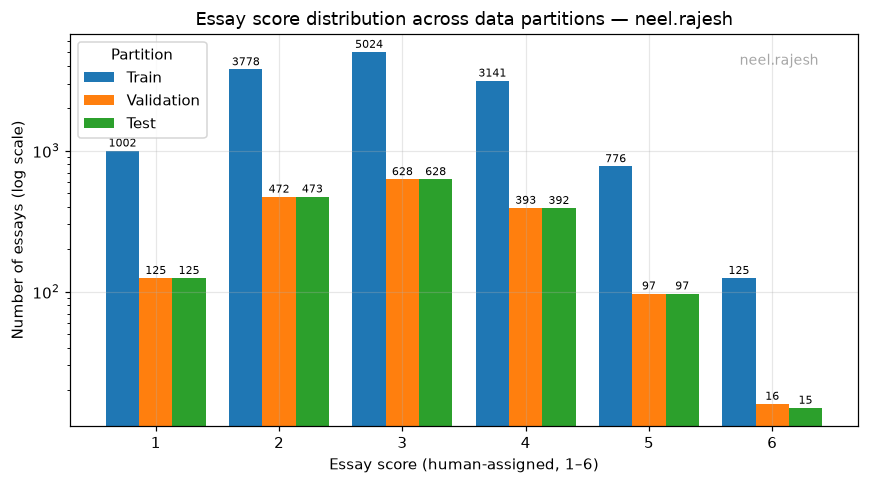

In [14]:
viz.plot_class_distribution(y_train, y_val, y_test)

#### Visualisation 2 — feature distributions by score band

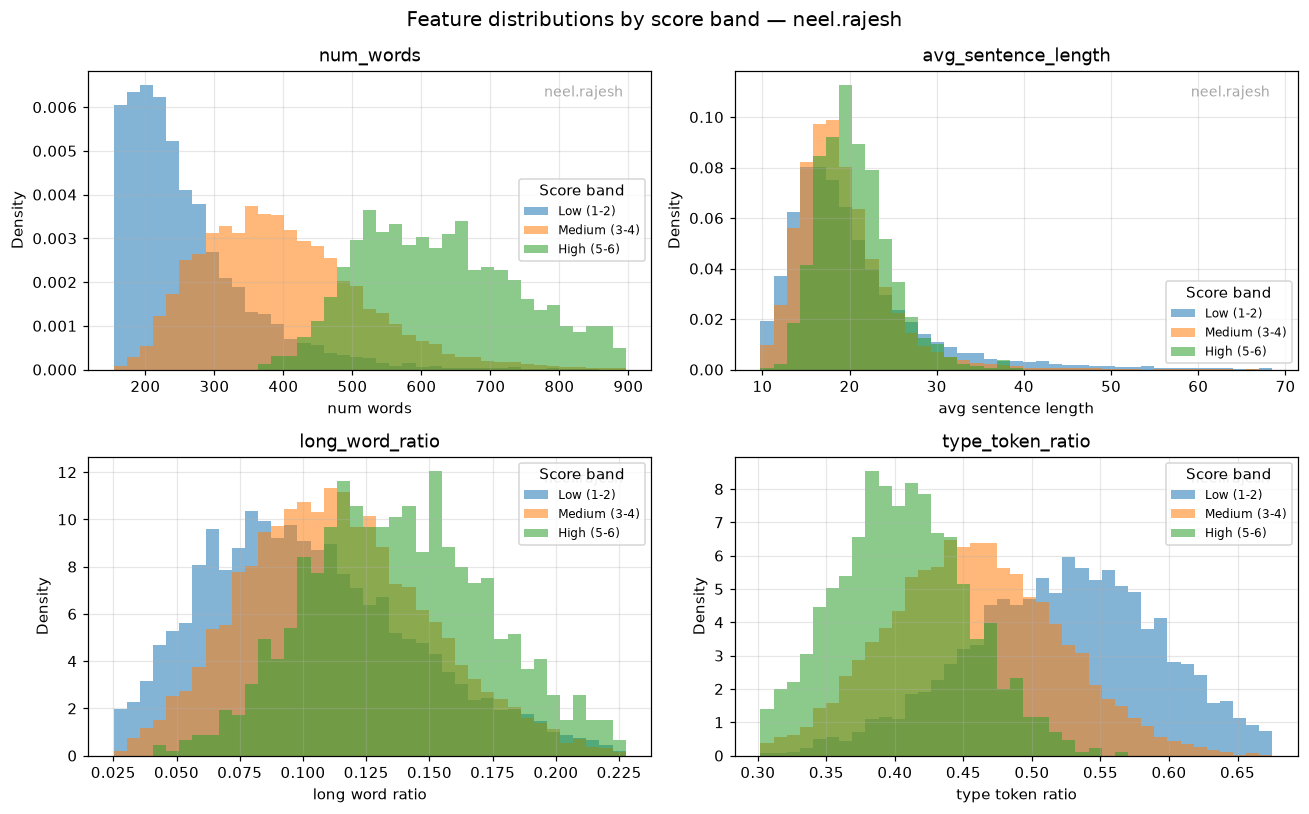

In [15]:
viz.plot_feature_histograms(
    X_train, y_train,
    ["num_words", "avg_sentence_length", "long_word_ratio", "type_token_ratio"],
)

#### Visualisation 3 — box plots of the strongest volume and style features

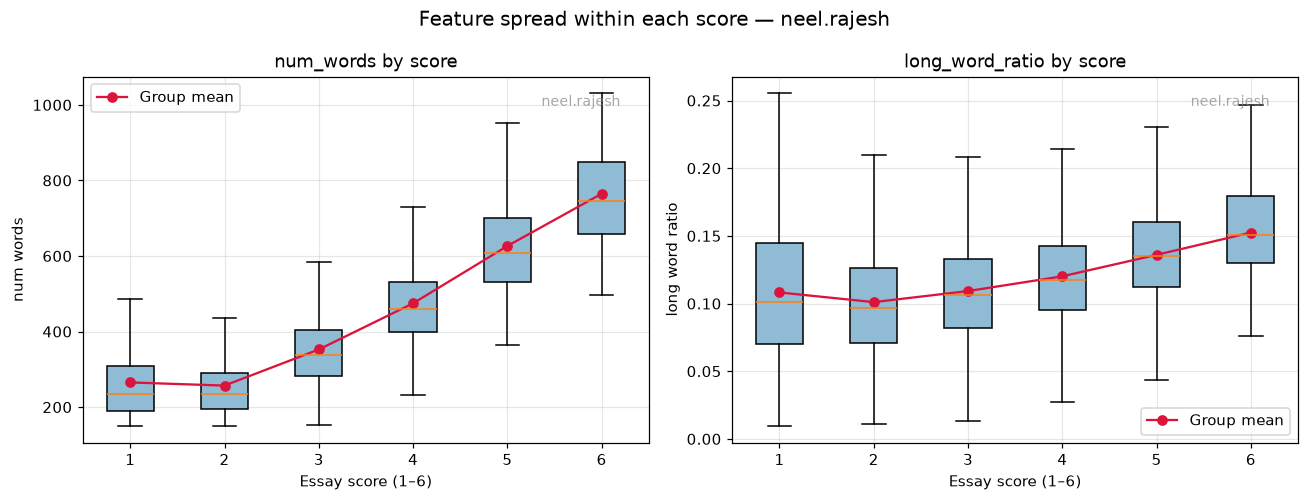

In [16]:
viz.plot_feature_boxplots(
    X_train, y_train, ["num_words", "long_word_ratio"],
)

#### Visualisation 4 — feature correlation matrix

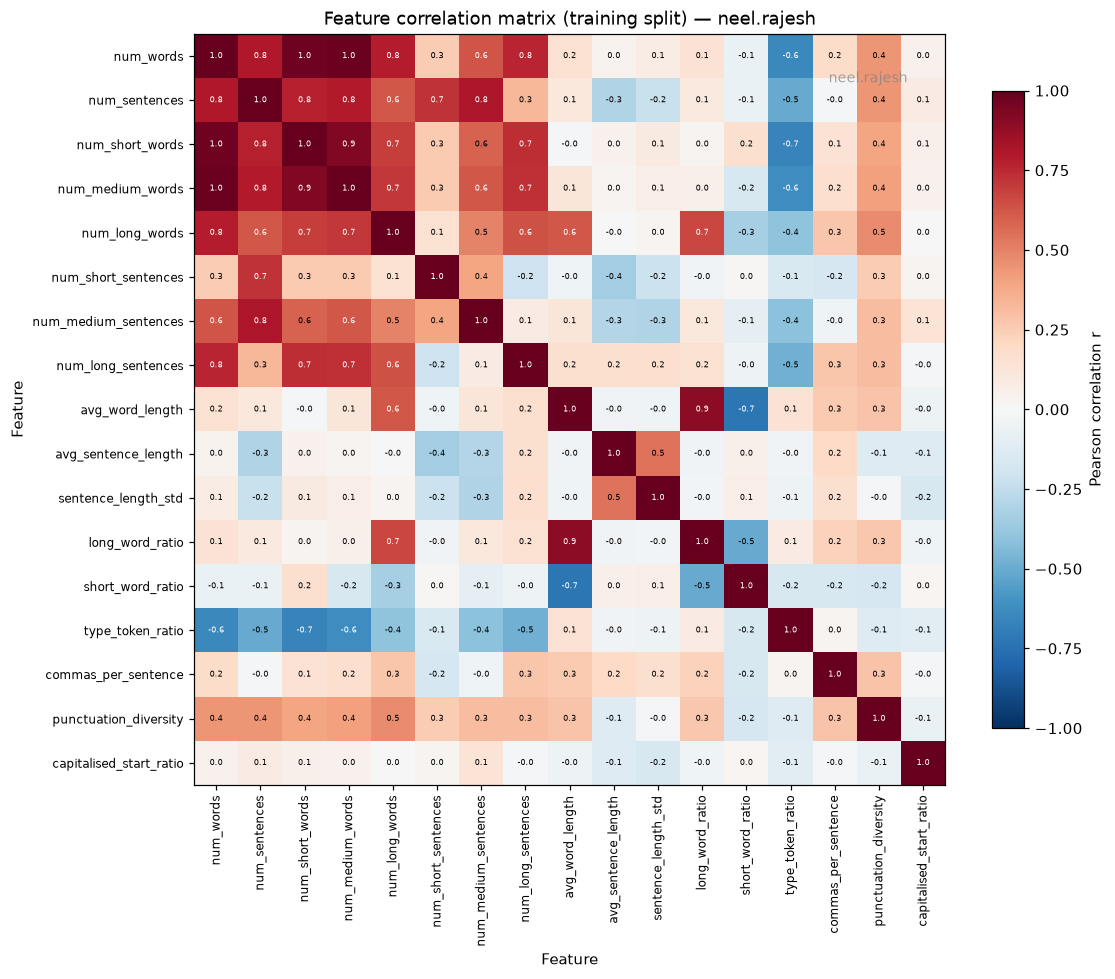

In [17]:
viz.plot_correlation_heatmap(X_train)

#### Visualisation 5 — two-feature scatter, coloured by score

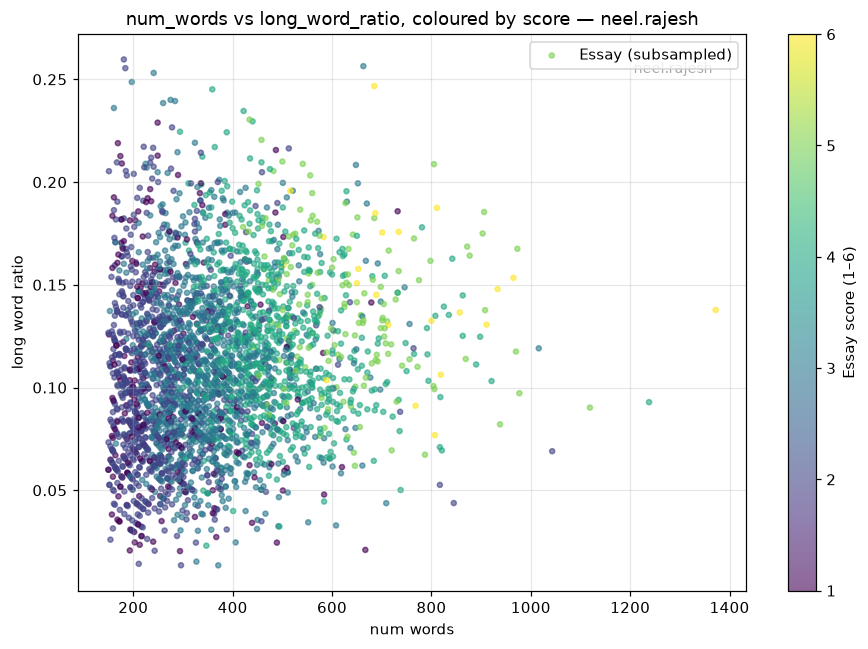

In [18]:
viz.plot_feature_scatter(
    X_train, y_train, "num_words", "long_word_ratio",
)

#### Visualisation 6 — standardised feature profile per score

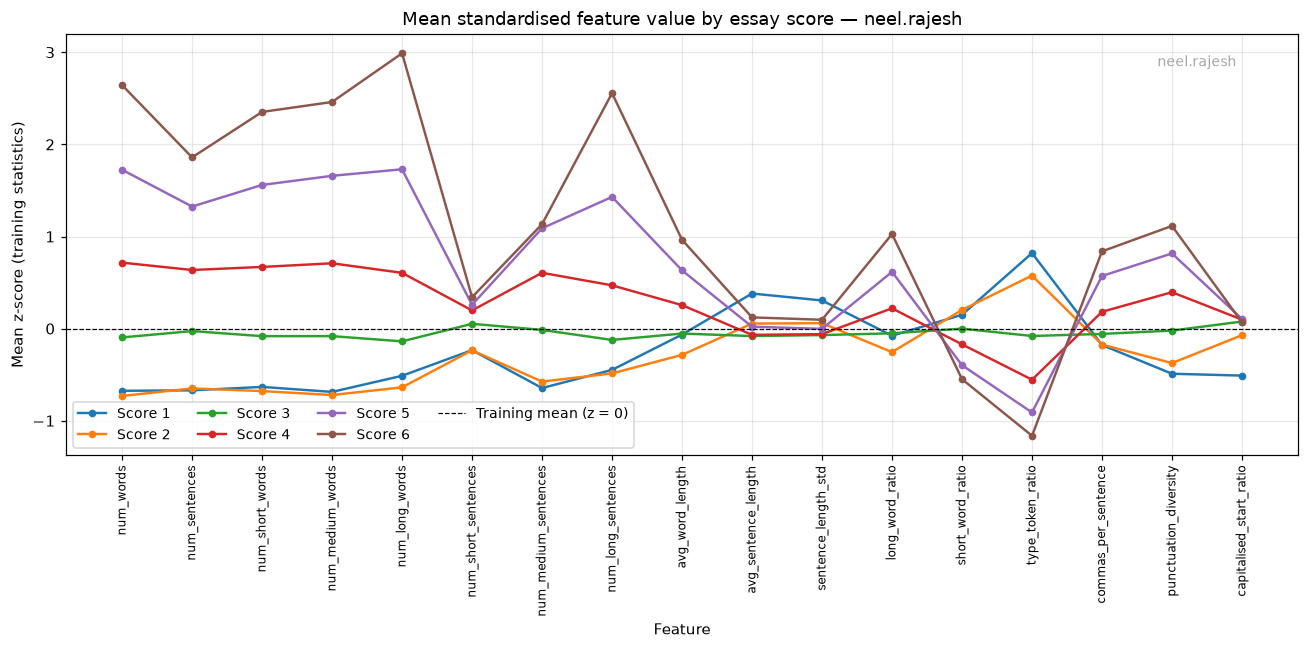

In [19]:
viz.plot_standardised_profiles(X_train_std, y_train)

### Observations from 1.2 (c)

**Class imbalance (Vis. 1).** The log-scaled bars make the imbalance stark: scores 3 and 4
together are ~59% of the data while score 6 is 0.9%. Stratification kept these proportions
identical across train, validation and test, but the test set still contains only ~16
score-6 essays — any per-class metric at that end of the range will be noisy, and KNN will
be structurally biased against predicting rare scores because the neighbourhood of almost
any point is dominated by 3s and 4s.

**Volume features dominate (Vis. 2, 3, 6).** `num_words` and its band counts shift strongly
and monotonically from score 2 upwards. The style ratios move far less in absolute terms,
but the standardised profile (Vis. 6) shows they still fan out consistently — once
z-scored, their smaller absolute range is no longer a disadvantage.

**The score-1 anomaly persists.** In Vis. 6 the score-1 line does not sit at the extreme of
the score-2 line for the length features; score-1 essays are *longer* than score-2 essays.
Length-based features therefore cannot separate the bottom two grades, and this is where
the model should be expected to make most of its errors.

**Redundancy is visible and severe (Vis. 4).** The five volume features are mutually
correlated between r = 0.8 and r = 1.0. `num_short_words` and `num_medium_words` each
correlate with `num_words` at r = 1.0 — to two significant figures they are the *same
measurement*, because short and medium words together are ~90% of any essay. Among the
style features, `avg_word_length` and `long_word_ratio` correlate at r = 0.9, which is
also near-duplication.

This matters more than it might appear. Z-scoring gives every column equal weight in the
distance, so five near-identical length columns give "essay length" roughly five times the
influence of any single style feature — the pipeline silently weights the feature set by
how many times each concept was measured, not by how informative each concept is. Two
defensible responses would be to drop the redundant band counts in favour of the ratios,
or to apply PCA before the distance computation. Neither is required by the assignment, so
the full set is retained here, but the effect should be remembered when reading 1.3's
tuning results.

**`type_token_ratio` runs backwards (Vis. 6).** It is *highest* for score 1 and *lowest*
for score 6 — the opposite of the "lexical diversity is good" intuition that motivated it.
The cause is mechanical rather than linguistic: unique-word count saturates as essays grow,
so the ratio falls with length, and length rises with score. It is still a useful feature
(it is strongly, if inversely, ordered) but it is really measuring length, not richness —
an honest reading of what the number does rather than what it was intended to do.

**Classes overlap heavily (Vis. 5).** The scatter shows a colour gradient rather than
separated clusters. This is the correct expectation for an ordinal scoring task, and it
predicts that KNN will get *close* to the right score far more often than it gets it
exactly right — which is why MAE and Pearson correlation in 1.4 are more informative
metrics here than plain accuracy.

## 1.3 K-Nearest Neighbours

### Design decisions

**Prediction rule — regression, i.e. the mean of the K neighbours.** Each query essay is
assigned the *average* score of its $K$ nearest training essays.

$$\hat y(x) = \frac{1}{K}\sum_{j=1}^{K} y_{(j)}$$

The course clarified that KNN here is to be used as a **regressor, not a classifier**:
"KNN for classification is taking the majority, and for regression is taking the average",
and a predicted score of 4.5/6 is intended rather than a defect. This is also the rule that
matches the four metrics 1.4 asks for — MAE, RMSE, $R^2$ and Pearson $r$ are all
regression measures. Essay scores are **ordinal**: 5 is genuinely closer to 6 than 1 is,
and averaging exploits that ordering, where a majority vote would discard it.

Because averaging returns a continuous value, there are no ties to break.

For the confusion matrix and the exact-match accuracy figure — both of which need discrete
grades — the continuous prediction is rounded to the nearest integer and clipped to the
valid range $[1,6]$. The rounding is used *only* for those two reporting purposes; every
regression metric is computed on the unrounded predictions.

**Distance metrics.**

$$d_{\text{euclidean}}(a,b)=\sqrt{\sum_i (a_i-b_i)^2}
\qquad
d_{\text{manhattan}}(a,b)=\sum_i |a_i-b_i|
\qquad
d_{\text{cosine}}(a,b)=1-\frac{a\cdot b}{\|a\|\,\|b\|}$$

**Efficiency.** The naive approach — instantiate a fresh model for each of the 24
configurations and recompute every distance — would compute the
$1{,}731 \times 13{,}846 \approx 24$ million pairwise distances 24 times over. Instead
`kneighbors` is called **once per distance metric** with $K=21$ (the largest value tested),
and the results for smaller $K$ are read off as prefixes of the same sorted neighbour list.
This makes the search 8x cheaper with no change to the results.

Euclidean and cosine distances are computed via matrix multiplication using
$\|a-b\|^2 = \|a\|^2 + \|b\|^2 - 2a\cdot b$. Manhattan admits no such factorisation, so it
is computed by explicit broadcasting over chunks of query rows to bound peak memory.

In [20]:
class KNN:
    """K-Nearest Neighbours *regressor* for essay scoring, implemented from scratch.

    The predicted score is the arithmetic mean of the K nearest training
    essays' scores, which treats the 1-6 grade as an ordinal quantity rather
    than an unordered label.

    Parameters
    ----------
    k : int
        Number of neighbours to average over.
    distance : {"euclidean", "manhattan", "cosine"}
        Distance metric used to rank neighbours.
    chunk_size : int
        Number of query rows processed at a time for the Manhattan metric,
        which cannot be factorised into a matrix product. Bounds peak memory.
    """

    SUPPORTED = ("euclidean", "manhattan", "cosine")

    def __init__(self, k=5, distance="euclidean", chunk_size=64):
        """Initialise the KNN essay scoring model."""
        if distance not in self.SUPPORTED:
            raise ValueError(
                f"distance must be one of {self.SUPPORTED}, got {distance!r}")
        self.k = k
        self.distance = distance
        self.chunk_size = chunk_size
        self.X_train = None
        self.y_train = None

    def fit(self, X_train, y_train):
        """Store the training feature vectors and scores.

        KNN is a lazy learner: there is no optimisation step, so fitting simply
        retains the training data (plus a few cached quantities used to speed up
        distance computation).

        Parameters
        ----------
        X_train : numpy.ndarray
            Standardised training features, shape (n_train, n_features).
        y_train : numpy.ndarray
            Training essay scores, shape (n_train,).

        Returns
        -------
        KNN
            self, to allow chaining.
        """
        self.X_train = np.asarray(X_train, dtype=float)
        self.y_train = np.asarray(y_train, dtype=float)
        # Cached for the euclidean expansion and the cosine denominator.
        self._train_sq_norms = (self.X_train ** 2).sum(axis=1)
        norms = np.sqrt(self._train_sq_norms)
        self._train_unit = self.X_train / np.where(norms == 0, 1.0, norms)[:, None]
        return self

    # ------------------------------------------------------------------
    # Distance computation
    # ------------------------------------------------------------------
    def _distances(self, X):
        """Compute the full query-to-training distance matrix.

        Parameters
        ----------
        X : numpy.ndarray
            Query features, shape (n_queries, n_features).

        Returns
        -------
        numpy.ndarray
            Distances, shape (n_queries, n_train).
        """
        X = np.asarray(X, dtype=float)

        if self.distance == "euclidean":
            # ||a - b||^2 = ||a||^2 + ||b||^2 - 2 a.b  - one matrix product
            # instead of an (n_queries x n_train x n_features) broadcast.
            sq = ((X ** 2).sum(axis=1)[:, None]
                  + self._train_sq_norms[None, :]
                  - 2.0 * (X @ self.X_train.T))
            # Tiny negative values can appear through floating-point error.
            return np.sqrt(np.maximum(sq, 0.0))

        if self.distance == "cosine":
            norms = np.sqrt((X ** 2).sum(axis=1))
            unit = X / np.where(norms == 0, 1.0, norms)[:, None]
            # Clipped because round-off can push the similarity marginally
            # outside [-1, 1].
            return 1.0 - np.clip(unit @ self._train_unit.T, -1.0, 1.0)

        # Manhattan: no factorisation exists, so broadcast in row chunks to
        # keep peak memory bounded.
        out = np.empty((len(X), len(self.X_train)), dtype=float)
        for start in range(0, len(X), self.chunk_size):
            stop = min(start + self.chunk_size, len(X))
            diff = X[start:stop, None, :] - self.X_train[None, :, :]
            out[start:stop] = np.abs(diff).sum(axis=2)
        return out

    def kneighbors(self, X, k=None):
        """Find the k nearest training neighbours of each query point.

        Uses ``argpartition`` to isolate the k smallest distances in linear time
        before sorting only those k, which is substantially cheaper than sorting
        all 13,846 training distances per query.

        Parameters
        ----------
        X : numpy.ndarray
            Query features, shape (n_queries, n_features).
        k : int, optional
            Number of neighbours; defaults to ``self.k``.

        Returns
        -------
        tuple of numpy.ndarray
            ``(distances, labels)``, each of shape (n_queries, k), ordered from
            nearest to furthest.
        """
        k = self.k if k is None else k
        d = self._distances(X)
        part = np.argpartition(d, kth=k - 1, axis=1)[:, :k]
        part_d = np.take_along_axis(d, part, axis=1)
        order = np.argsort(part_d, axis=1)
        idx = np.take_along_axis(part, order, axis=1)
        return np.take_along_axis(d, idx, axis=1), self.y_train[idx]

    # ------------------------------------------------------------------
    # Aggregation
    # ------------------------------------------------------------------
    @staticmethod
    def _aggregate(neighbour_labels):
        """Combine the neighbours' scores into one prediction, by averaging.

        This is the regression form of KNN. Averaging uses the fact that essay
        scores are ordinal - a neighbourhood of {3, 4} should predict 3.5, not
        arbitrarily pick one of them - and it is the rule the four evaluation
        metrics in 1.4 are designed for.

        Parameters
        ----------
        neighbour_labels : numpy.ndarray
            Scores of the k neighbours, shape (n_queries, k).

        Returns
        -------
        numpy.ndarray
            Continuous predicted scores, shape (n_queries,).
        """
        return neighbour_labels.mean(axis=1)

    def predict(self, X):
        """Predict essay scores for the given feature vectors.

        Parameters
        ----------
        X : numpy.ndarray
            Query features, shape (n_queries, n_features).

        Returns
        -------
        numpy.ndarray
            Continuous predicted essay scores, shape (n_queries,).

        Raises
        ------
        RuntimeError
            If called before ``fit``.
        """
        if self.X_train is None:
            raise RuntimeError("KNN must be fitted before predict().")
        _, labels = self.kneighbors(X, self.k)
        return self._aggregate(labels)


def to_grade(predictions, low=1, high=6):
    """Round continuous predictions to the nearest valid integer grade.

    Used only for the confusion matrix and the exact-match accuracy figure;
    every regression metric is computed on the unrounded predictions.

    Parameters
    ----------
    predictions : numpy.ndarray
        Continuous predicted scores.
    low, high : int
        Inclusive bounds of the valid grade range.

    Returns
    -------
    numpy.ndarray
        Integer grades in [low, high].
    """
    return np.clip(np.rint(np.asarray(predictions, dtype=float)),
                   low, high).astype(int)


print("KNN (regression form) and to_grade defined.")

KNN (regression form) and to_grade defined.


### Evaluation metrics, implemented from scratch

No `sklearn` is used anywhere. Each metric is written directly from its definition:

$$\text{MAE}=\frac1n\sum|y_i-\hat y_i|
\qquad
\text{RMSE}=\sqrt{\frac1n\sum (y_i-\hat y_i)^2}$$

$$R^2 = 1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}
\qquad
r=\frac{\sum (y_i-\bar y)(\hat y_i-\bar{\hat y})}
{\sqrt{\sum (y_i-\bar y)^2 \sum (\hat y_i-\bar{\hat y})^2}}$$

In [21]:
class ScoringMetrics:
    """Evaluation metrics for essay score prediction, implemented from scratch.

    All methods are static and operate on plain NumPy arrays. No sklearn or
    scipy function is used anywhere - the course required these to be
    hand-written from their definitions.

    The four assignment metrics (MAE, RMSE, R^2, Pearson r) are computed on the
    raw continuous predictions. ``Accuracy`` and ``Within_1`` are reported as
    supplementary context and use predictions rounded to integer grades.
    """

    @staticmethod
    def mean_absolute_error(y_true, y_pred):
        """Mean absolute error: the average magnitude of the prediction error."""
        return float(np.mean(np.abs(np.asarray(y_true, float)
                                    - np.asarray(y_pred, float))))

    @staticmethod
    def root_mean_squared_error(y_true, y_pred):
        """Root mean squared error, which penalises large errors quadratically."""
        err = np.asarray(y_true, float) - np.asarray(y_pred, float)
        return float(np.sqrt(np.mean(err ** 2)))

    @staticmethod
    def r2_score(y_true, y_pred):
        """Coefficient of determination.

        The fraction of variance in the true scores explained by the model.
        A model that always predicts the mean scores 0; a perfect model scores 1;
        negative values mean the model is worse than predicting the mean.
        """
        y_true = np.asarray(y_true, float)
        y_pred = np.asarray(y_pred, float)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - y_true.mean()) ** 2)
        return float(1.0 - ss_res / ss_tot) if ss_tot > 0 else float("nan")

    @staticmethod
    def pearson_correlation(y_true, y_pred):
        """Pearson correlation coefficient between true and predicted scores.

        Measures linear association: whether the model ranks essays correctly,
        independently of any constant offset or scaling in its predictions.
        Returns NaN if either input is constant (undefined correlation).
        """
        y_true = np.asarray(y_true, float)
        y_pred = np.asarray(y_pred, float)
        a = y_true - y_true.mean()
        b = y_pred - y_pred.mean()
        denom = np.sqrt(np.sum(a ** 2) * np.sum(b ** 2))
        return float(np.sum(a * b) / denom) if denom > 0 else float("nan")

    @staticmethod
    def accuracy(y_true, y_pred):
        """Fraction of essays whose *rounded* prediction matches the truth."""
        return float(np.mean(np.asarray(y_true) == to_grade(y_pred)))

    @staticmethod
    def within_one(y_true, y_pred):
        """Fraction of predictions within one grade of the true score.

        Not requested by the assignment, but a natural tolerance measure for an
        ordinal scoring task where adjacent grades are genuinely hard to separate.
        """
        return float(np.mean(np.abs(np.asarray(y_true, float)
                                    - np.asarray(y_pred, float)) <= 1))

    @classmethod
    def evaluate(cls, y_true, y_pred):
        """Compute every metric at once.

        Returns
        -------
        dict
            Keys ``MAE``, ``RMSE``, ``R2``, ``Pearson_r``, ``Accuracy``,
            ``Within_1``.
        """
        return {
            "MAE": cls.mean_absolute_error(y_true, y_pred),
            "RMSE": cls.root_mean_squared_error(y_true, y_pred),
            "R2": cls.r2_score(y_true, y_pred),
            "Pearson_r": cls.pearson_correlation(y_true, y_pred),
            "Accuracy": cls.accuracy(y_true, y_pred),
            "Within_1": cls.within_one(y_true, y_pred),
        }


def confusion_matrix(y_true, y_pred, labels):
    """Build a confusion matrix from scratch.

    Parameters
    ----------
    y_true, y_pred : array-like
        True and predicted labels (predictions must already be integer grades).
    labels : array-like
        Ordered label set defining the matrix rows and columns.

    Returns
    -------
    numpy.ndarray
        Integer matrix where entry (i, j) counts samples whose true label is
        ``labels[i]`` and whose predicted label is ``labels[j]``.
    """
    labels = list(labels)
    index = {lab: i for i, lab in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=int)
    for truth, pred in zip(np.asarray(y_true), np.asarray(y_pred)):
        matrix[index[truth], index[pred]] += 1
    return matrix


print("ScoringMetrics and confusion_matrix defined.")

ScoringMetrics and confusion_matrix defined.


### 1.3 (b) Hyperparameter tuning — all 24 configurations on the validation set

Every configuration is scored on **all** the metrics that will later be used on the test
set, as the course required, rather than on a single number.

**Selection rule.** The course was explicit that no one metric should decide the winner:
*"There is no one desirable metric. You need to search for a model that performs well
across all the metrics. For e.g. a system with high correlation score is useless if MSE is
very high."*

So the configurations are combined by **mean rank across the four assignment metrics**:
each configuration is ranked on MAE (ascending), RMSE (ascending), $R^2$ (descending) and
Pearson $r$ (descending), and the four ranks are averaged. The lowest mean rank wins.

Ranking rather than averaging the raw values is deliberate — the four metrics live on
different scales, so averaging them directly would let RMSE dominate $R^2$ for arbitrary
reasons. Ranks make them commensurable, and a configuration only wins if it is
*consistently* good rather than excellent on one metric and poor on the rest.

In [22]:
def tune_knn(X_train, y_train, X_val, y_val, k_values, metrics):
    """Evaluate every (distance metric, K) combination on the validation set.

    The neighbour search is performed once per distance metric using the largest
    K requested; results for smaller K are prefixes of the same sorted neighbour
    list. This avoids recomputing the ~24 million pairwise distances for every
    configuration.

    Parameters
    ----------
    X_train, y_train : numpy.ndarray
        Standardised training features and scores.
    X_val, y_val : numpy.ndarray
        Standardised validation features and scores.
    k_values : sequence of int
        Values of K to evaluate.
    metrics : sequence of str
        Distance metric names.

    Returns
    -------
    pandas.DataFrame
        One row per configuration, with every evaluation metric.
    """
    k_max = max(k_values)
    rows = []
    for metric in metrics:
        model = KNN(k=k_max, distance=metric).fit(X_train, y_train)
        _, labels = model.kneighbors(X_val, k=k_max)
        for k in k_values:
            preds = model._aggregate(labels[:, :k])
            row = {"Distance Metric": metric.capitalize(), "K": k}
            row.update(ScoringMetrics.evaluate(y_val, preds))
            rows.append(row)
    return pd.DataFrame(rows)


def rank_configurations(results,
                        lower_is_better=("MAE", "RMSE"),
                        higher_is_better=("R2", "Pearson_r")):
    """Rank configurations by their average rank across all four metrics.

    Each metric is ranked separately (1 = best), then the ranks are averaged.
    This implements the course's instruction not to select K on a single
    metric: a configuration wins only if it performs well across all of them.

    Ranks are used rather than the raw values because the four metrics are on
    incomparable scales, so a direct average would be dominated by whichever
    metric happens to have the largest numeric spread.

    Parameters
    ----------
    results : pandas.DataFrame
        Output of ``tune_knn``.
    lower_is_better, higher_is_better : sequence of str
        Metric column names, split by their preferred direction.

    Returns
    -------
    pandas.DataFrame
        A copy of ``results`` with one ``rank_<metric>`` column per metric and a
        ``mean_rank`` column, sorted best-first.
    """
    ranked = results.copy()
    rank_columns = []
    for metric in lower_is_better:
        ranked[f"rank_{metric}"] = results[metric].rank(ascending=True)
        rank_columns.append(f"rank_{metric}")
    for metric in higher_is_better:
        ranked[f"rank_{metric}"] = results[metric].rank(ascending=False)
        rank_columns.append(f"rank_{metric}")
    ranked["mean_rank"] = ranked[rank_columns].mean(axis=1)
    return ranked.sort_values("mean_rank").reset_index(drop=True)


K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21]
DISTANCE_METRICS = ["euclidean", "manhattan", "cosine"]

results = tune_knn(X_train_std, y_train, X_val_std, y_val,
                   K_VALUES, DISTANCE_METRICS)
ranked_results = rank_configurations(results)

pd.set_option("display.width", 160)
print(f"{len(results)} configurations evaluated on the validation set "
      f"({len(y_val):,} essays).")

24 configurations evaluated on the validation set (1,731 essays).


In [23]:
# The full validation table, in the layout the assignment specifies:
# one row per (distance metric, K), every metric reported.
display_table = results.copy()
metric_columns = ["MAE", "RMSE", "R2", "Pearson_r", "Accuracy", "Within_1"]
display_table[metric_columns] = display_table[metric_columns].round(4)
display_table

,Distance Metric,K,MAE,RMSE,R2,Pearson_r,Accuracy,Within_1
0,Euclidean,1,0.6592,0.9496,0.1752,0.5849,0.4477,0.9076
1,Euclidean,3,0.5796,0.7609,0.4705,0.7006,0.5136,0.8793
2,Euclidean,5,0.5556,0.7256,0.5185,0.7245,0.5373,0.8787
3,Euclidean,7,0.5519,0.7151,0.5323,0.7319,0.5471,0.8746
4,Euclidean,9,0.5472,0.7069,0.5430,0.7381,0.5459,0.8746
5,Euclidean,11,0.5410,0.6995,0.5525,0.7440,0.5505,0.8689
6,Euclidean,15,0.5349,0.6920,0.5620,0.7501,0.5534,0.8706
7,Euclidean,21,0.5353,0.6912,0.5630,0.7508,0.5540,0.8677
8,Manhattan,1,0.6384,0.9250,0.2175,0.6001,0.4598,0.9122
9,Manhattan,3,0.5742,0.7533,0.4810,0.7058,0.5274,0.8908


In [24]:
# Selection across ALL metrics by mean rank, not on any single one.
best_row = ranked_results.iloc[0]
BEST_K = int(best_row["K"])
BEST_METRIC = str(best_row["Distance Metric"]).lower()

print("Top 5 configurations by mean rank across MAE, RMSE, R2 and Pearson r")
print("=" * 78)
print(ranked_results.head(5)[
    ["Distance Metric", "K", "MAE", "RMSE", "R2", "Pearson_r", "mean_rank"]
].round(4).to_string(index=False))

print("\nSelected configuration")
print("-" * 44)
print(f"  distance metric : {BEST_METRIC}")
print(f"  K               : {BEST_K}")
print(f"  mean rank       : {best_row['mean_rank']:.2f} (of 24 configurations)")
print("-" * 44)
for name in metric_columns:
    print(f"  {name:<10}: {best_row[name]:.4f}")

print("\nBest configuration per distance metric (by mean rank):")
best_per_metric = (ranked_results.sort_values("mean_rank")
                   .groupby("Distance Metric", as_index=False).first())
print(best_per_metric[["Distance Metric", "K", "MAE", "RMSE", "R2",
                       "Pearson_r", "mean_rank"]].round(4).to_string(index=False))

print("\nFor comparison, the winner under each metric taken alone:")
for metric, ascending in [("MAE", True), ("RMSE", True),
                          ("R2", False), ("Pearson_r", False)]:
    row = results.loc[results[metric].idxmin() if ascending
                      else results[metric].idxmax()]
    print(f"  {metric:<10}-> {row['Distance Metric']:<10} K={int(row['K']):<3} "
          f"({row[metric]:.4f})")

Top 5 configurations by mean rank across MAE, RMSE, R2 and Pearson r
Distance Metric  K    MAE   RMSE     R2  Pearson_r  mean_rank
      Euclidean 21 0.5353 0.6912 0.5630     0.7508       1.50
      Euclidean 15 0.5349 0.6920 0.5620     0.7501       1.75
      Manhattan 15 0.5351 0.6947 0.5586     0.7483       2.75
      Manhattan 21 0.5361 0.6976 0.5548     0.7457       4.00
      Euclidean 11 0.5410 0.6995 0.5525     0.7440       5.50

Selected configuration
--------------------------------------------
  distance metric : euclidean
  K               : 21
  mean rank       : 1.50 (of 24 configurations)
--------------------------------------------
  MAE       : 0.5353
  RMSE      : 0.6912
  R2        : 0.5630
  Pearson_r : 0.7508
  Accuracy  : 0.5540
  Within_1  : 0.8677

Best configuration per distance metric (by mean rank):
Distance Metric  K    MAE   RMSE     R2  Pearson_r  mean_rank
         Cosine 21 0.5615 0.7263 0.5175     0.7271      13.25
      Euclidean 21 0.5353 0.6912 0.563

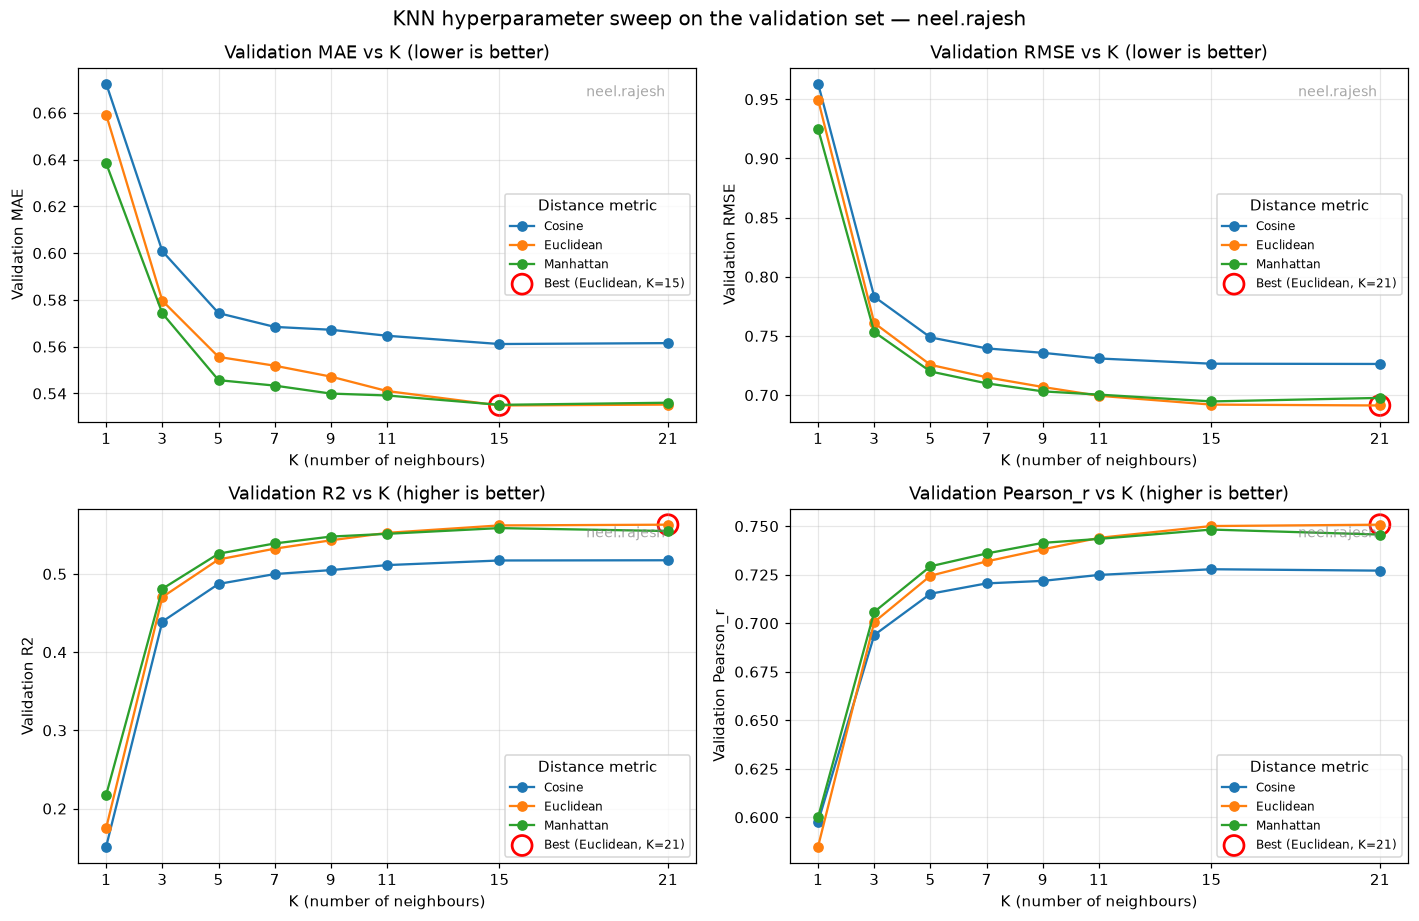

In [25]:
class ResultsVisualizer:
    """Plots for the KNN tuning and evaluation results.

    Presentational only: every method receives already-computed results and is
    responsible solely for drawing. All figures carry a title, axis labels, a
    legend and the author's username.

    Parameters
    ----------
    username : str
        Username stamped onto every figure.
    """

    def __init__(self, username=USERNAME):
        """Store the watermark text used by every plot."""
        self.username = username

    def plot_k_sweep(self, results, metric_columns=("MAE", "RMSE", "R2", "Pearson_r"),
                     lower_is_better=("MAE", "RMSE")):
        """Plot every error measure against K, one panel per metric.

        The course expects the error measures to be plotted against both K and
        the distance metric, so each panel carries one line per distance metric.
        """
        n = len(metric_columns)
        fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(13, 8.5))
        axes = np.atleast_1d(axes).ravel()
        for ax, column in zip(axes, metric_columns):
            for name, group in results.groupby("Distance Metric"):
                group = group.sort_values("K")
                ax.plot(group["K"], group[column], "o-", label=name)
            best = (results.loc[results[column].idxmin()]
                    if column in lower_is_better
                    else results.loc[results[column].idxmax()])
            ax.scatter([best["K"]], [best[column]], s=170, facecolors="none",
                       edgecolors="red", linewidths=1.8,
                       label=f"Best ({best['Distance Metric']}, K={int(best['K'])})")
            direction = "lower is better" if column in lower_is_better \
                else "higher is better"
            ax.set_title(f"Validation {column} vs K ({direction})")
            ax.set_xlabel("K (number of neighbours)")
            ax.set_ylabel(f"Validation {column}")
            ax.set_xticks(sorted(results["K"].unique()))
            ax.legend(title="Distance metric", fontsize=8)
            add_watermark(ax, self.username)
        for ax in axes[n:]:
            ax.axis("off")
        fig.suptitle(
            f"KNN hyperparameter sweep on the validation set — {self.username}",
            fontsize=13)
        plt.tight_layout()
        plt.show()

    def plot_confusion_matrix(self, matrix, labels, title):
        """Annotated heat map of a confusion matrix, row-normalised.

        Row normalisation shows, for each true score, where its essays were
        actually sent — which is the question that matters under heavy class
        imbalance.
        """
        row_sums = matrix.sum(axis=1, keepdims=True)
        normalised = matrix / np.where(row_sums == 0, 1, row_sums)
        fig, ax = plt.subplots(figsize=(7.4, 6.2))
        im = ax.imshow(normalised, cmap="Blues", vmin=0, vmax=1)
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, f"{matrix[i, j]}\n{normalised[i, j]*100:.0f}%",
                        ha="center", va="center", fontsize=8,
                        color="white" if normalised[i, j] > 0.5 else "black")
        ax.plot([], [], "s", color="#08306b", label="High row share")
        ax.set_xticks(range(len(labels)))
        ax.set_yticks(range(len(labels)))
        ax.set_xticklabels(labels)
        ax.set_yticklabels(labels)
        fig.colorbar(im, ax=ax, shrink=0.85, label="Share of true-class row")
        ax.set_title(f"{title} — {self.username}")
        ax.set_xlabel("Predicted essay score (rounded)")
        ax.set_ylabel("True essay score")
        ax.legend(loc="upper left", fontsize=8)
        ax.grid(False)
        plt.tight_layout()
        add_watermark(ax, self.username)
        plt.show()

    def plot_prediction_scatter(self, y_true, y_pred, username=None):
        """Continuous predictions against true scores, as a box plot per grade.

        Because the predictions are continuous while the truth is discrete, a
        box plot per true grade shows the distribution of predicted values much
        more clearly than a scatter of overlapping points would.
        """
        username = username or self.username
        grades = np.arange(1, 7)
        data = [np.asarray(y_pred)[np.asarray(y_true) == g] for g in grades]
        fig, ax = plt.subplots(figsize=(9, 5.4))
        bp = ax.boxplot(data, tick_labels=grades, showfliers=False,
                        patch_artist=True)
        for patch in bp["boxes"]:
            patch.set_facecolor("#8fbcd4")
        ax.plot(grades, grades, "--", color="crimson", linewidth=1.6,
                label="Perfect prediction (y = x)")
        ax.plot(grades, [d.mean() for d in data], "o-", color="#28527a",
                label="Mean prediction")
        ax.set_title(f"Continuous predictions by true score — {username}")
        ax.set_xlabel("True essay score")
        ax.set_ylabel("Predicted score (continuous)")
        ax.legend()
        add_watermark(ax, username)
        plt.tight_layout()
        plt.show()

    def plot_error_profile(self, y_true, y_pred, labels):
        """Per-score MAE alongside the number of test essays in each score.

        Pairs each class's error with its support, making clear that the large
        errors occur exactly where the training data is thinnest.
        """
        maes, counts = [], []
        for label in labels:
            mask = np.asarray(y_true) == label
            counts.append(int(mask.sum()))
            maes.append(ScoringMetrics.mean_absolute_error(
                np.asarray(y_true)[mask], np.asarray(y_pred)[mask]))
        fig, ax = plt.subplots(figsize=(9, 5))
        bars = ax.bar(labels, maes, color="#c46a5a", label="Per-score MAE")
        ax.bar_label(bars, fmt="%.2f", fontsize=9)
        ax.set_title(f"Test error by true essay score — {self.username}")
        ax.set_xlabel("True essay score")
        ax.set_ylabel("Mean absolute error")
        twin = ax.twinx()
        twin.plot(labels, counts, "o--", color="#28527a",
                  label="Test essays in class")
        twin.set_ylabel("Number of test essays (support)")
        twin.grid(False)
        handles, texts = ax.get_legend_handles_labels()
        h2, t2 = twin.get_legend_handles_labels()
        ax.legend(handles + h2, texts + t2, loc="upper center")
        add_watermark(ax, self.username)
        plt.tight_layout()
        plt.show()


results_viz = ResultsVisualizer(USERNAME)
results_viz.plot_k_sweep(results)


### Discussion — how K and the distance metric affect performance

**Selected configuration: Euclidean distance, K = 21** (mean rank 1.50 of 24).

#### Effect of K

Every metric improves sharply as K grows, then flattens:

| Euclidean, K | 1 | 3 | 5 | 7 | 9 | 11 | 15 | 21 |
|---|---|---|---|---|---|---|---|---|
| MAE | 0.659 | 0.580 | 0.556 | 0.552 | 0.547 | 0.541 | **0.535** | 0.535 |
| RMSE | 0.950 | 0.761 | 0.726 | 0.715 | 0.707 | 0.700 | 0.692 | **0.691** |
| $R^2$ | 0.175 | 0.471 | 0.519 | 0.532 | 0.543 | 0.553 | 0.562 | **0.563** |

This is the bias–variance trade-off. At $K=1$ each prediction rests on a single training
essay, so noise in that one human-assigned score passes straight through — $R^2$ of 0.175,
the worst result in the sweep. Averaging more neighbours cancels that noise. Because human
essay scoring is itself noisy, the variance removed far outweighs the bias introduced.

The gain is heavily front-loaded: $K=1 \to 3$ alone moves $R^2$ from 0.175 to 0.471, while
$K=15 \to 21$ moves it by 0.001. The curve is essentially flat past $K \approx 15$.

#### Why selecting on a single metric would have been wrong

The course's instruction not to pick K on one metric is borne out exactly here — the four
metrics genuinely disagree:

| Metric taken alone | Winner |
|---|---|
| MAE | Euclidean, **K = 15** (0.5349) |
| RMSE | Euclidean, **K = 21** (0.6912) |
| $R^2$ | Euclidean, **K = 21** (0.5630) |
| Pearson $r$ | Euclidean, **K = 21** (0.7508) |

MAE prefers $K=15$; the other three prefer $K=21$. The difference is tiny (MAE 0.5349 vs
0.5353) but it is a real conflict, and it has a clear interpretation: $K=21$ makes slightly
larger *typical* errors while making fewer *large* ones, because a wider average is pulled
less far by an unusual neighbour. Since RMSE squares the errors, it rewards exactly that.

The mean-rank rule selects $K=21$ (rank 1.50) over $K=15$ (rank 1.75) — a genuinely
marginal call, and either would be defensible. What matters is that the decision was made
across all four metrics rather than by whichever one happened to be quoted first.

#### Effect of the distance metric

| Metric | Best K | MAE | RMSE | $R^2$ | Mean rank |
|---|---|---|---|---|---|
| **Euclidean** | 21 | 0.5353 | **0.6912** | **0.5630** | **1.50** |
| Manhattan | 15 | **0.5351** | 0.6947 | 0.5586 | 2.75 |
| Cosine | 21 | 0.5615 | 0.7263 | 0.5175 | 13.25 |

**Euclidean and Manhattan are near-identical** — 0.0002 apart on MAE. After Z-scoring all
17 features occupy comparable ranges with no extreme outliers, and the two metrics then
differ only in how per-dimension differences are aggregated. Manhattan, being less
sensitive to a single unusual coordinate, reaches its optimum at a slightly smaller K.

**Cosine is clearly worst** — every one of its eight configurations ranks below every
Euclidean and Manhattan configuration. The reason is instructive: cosine distance measures
only the *angle* between feature vectors and discards their *magnitude*. On standardised
features, magnitude is precisely the signal "this essay is far above average on all the
length dimensions" — and Section 1.1 established that length is the strongest single
predictor in this dataset. Cosine therefore throws away the most discriminative
information available and keeps only the relative shape of the feature profile. It suits
data where scale is a nuisance (raw term-frequency vectors, say); here it is actively
harmful.


## 1.4 Evaluation on the Test Set

The winning configuration from the validation sweep is now applied, once, to the
held-out test set. The test data has been untouched to this point — it took no part in
feature design, in fitting the normalisation statistics, or in hyperparameter selection.

In [26]:
final_model = KNN(k=BEST_K, distance=BEST_METRIC).fit(X_train_std, y_train)
y_test_pred = final_model.predict(X_test_std)          # continuous
y_test_grade = to_grade(y_test_pred)                   # rounded, for the confusion matrix

test_metrics = ScoringMetrics.evaluate(y_test, y_test_pred)

print(f"Final model : KNN(k={BEST_K}, distance='{BEST_METRIC}'), regression form")
print(f"Test set    : {len(y_test):,} essays\n")
print("=" * 52)
print(f"{'(a) Mean Absolute Error':<34}{test_metrics['MAE']:>10.4f}")
print(f"{'(b) Root Mean Squared Error':<34}{test_metrics['RMSE']:>10.4f}")
print(f"{'(c) R-squared Score':<34}{test_metrics['R2']:>10.4f}")
print(f"{'(d) Pearson Correlation':<34}{test_metrics['Pearson_r']:>10.4f}")
print("=" * 52)
print(f"{'    Exact match after rounding':<34}{test_metrics['Accuracy']:>10.4f}")
print(f"{'    Within one grade':<34}{test_metrics['Within_1']:>10.4f}")
print("=" * 52)

print(f"\nPredictions are continuous, as intended for the regression form:")
print(f"  range          : [{y_test_pred.min():.3f}, {y_test_pred.max():.3f}]")
print(f"  distinct values: {len(np.unique(y_test_pred)):,} "
      f"(a classifier would produce at most 6)")

Final model : KNN(k=21, distance='euclidean'), regression form
Test set    : 1,730 essays

(a) Mean Absolute Error               0.5349
(b) Root Mean Squared Error           0.7050
(c) R-squared Score                   0.5434
(d) Pearson Correlation               0.7386
    Exact match after rounding        0.5618
    Within one grade                  0.8653

Predictions are continuous, as intended for the regression form:
  range          : [1.381, 5.381]
  distinct values: 83 (a classifier would produce at most 6)


In [27]:
# Compare validation and test performance to check for overfitting to the
# validation set during hyperparameter selection.
comparison = pd.DataFrame({
    "validation": {m: best_row[m] for m in
                   ["MAE", "RMSE", "R2", "Pearson_r", "Accuracy", "Within_1"]},
    "test": test_metrics,
}).round(4)
comparison.index.name = "metric"
comparison

,validation,test
metric,,
MAE,0.5353,0.5349
RMSE,0.6912,0.7050
R2,0.5630,0.5434
Pearson_r,0.7508,0.7386
Accuracy,0.5540,0.5618
Within_1,0.8677,0.8653


Confusion matrix, predictions rounded to the nearest grade
(rows = true score, columns = predicted score):

        pred_1  pred_2  pred_3  pred_4  pred_5  pred_6
true_1       2      81      37       5       0       0
true_2       1     316     140      15       1       0
true_3       0     119     414      89       6       0
true_4       0       2     163     209      18       0
true_5       0       0       6      60      31       0
true_6       0       0       0       4      11       0


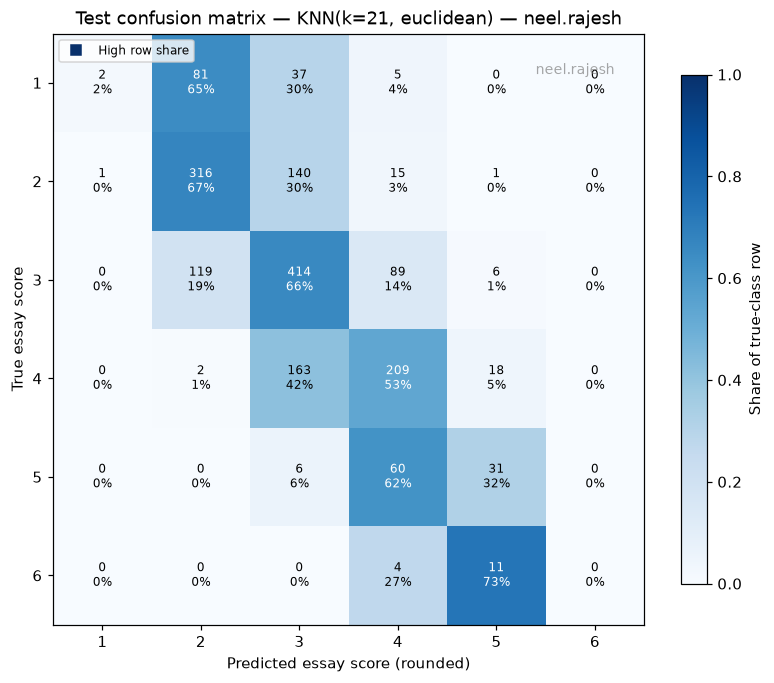

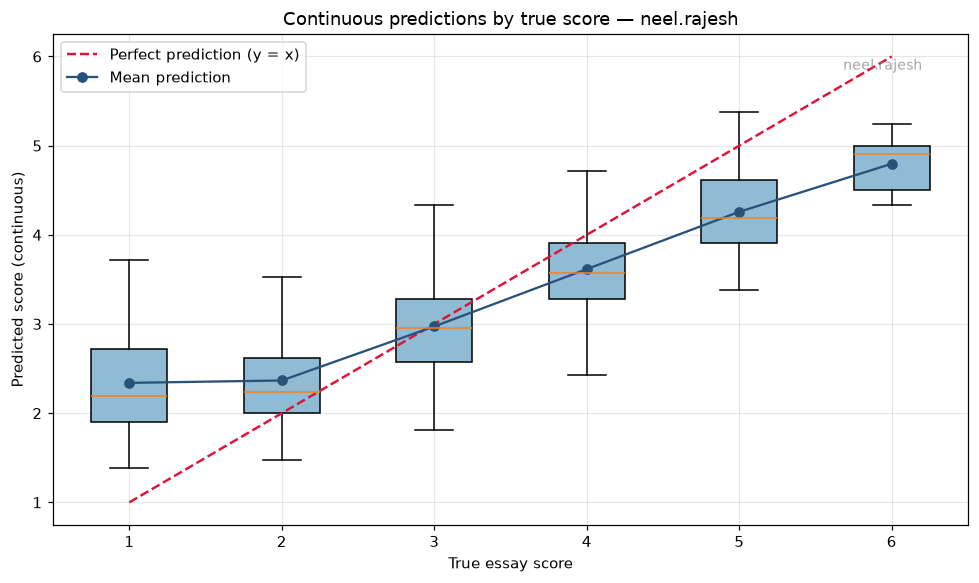

In [28]:
SCORE_LABELS = list(range(1, 7))
cm = confusion_matrix(y_test, y_test_grade, SCORE_LABELS)

print("Confusion matrix, predictions rounded to the nearest grade")
print("(rows = true score, columns = predicted score):\n")
print(pd.DataFrame(cm, index=[f"true_{s}" for s in SCORE_LABELS],
                   columns=[f"pred_{s}" for s in SCORE_LABELS]))

results_viz.plot_confusion_matrix(
    cm, SCORE_LABELS, f"Test confusion matrix — KNN(k={BEST_K}, {BEST_METRIC})")

results_viz.plot_prediction_scatter(y_test, y_test_pred)

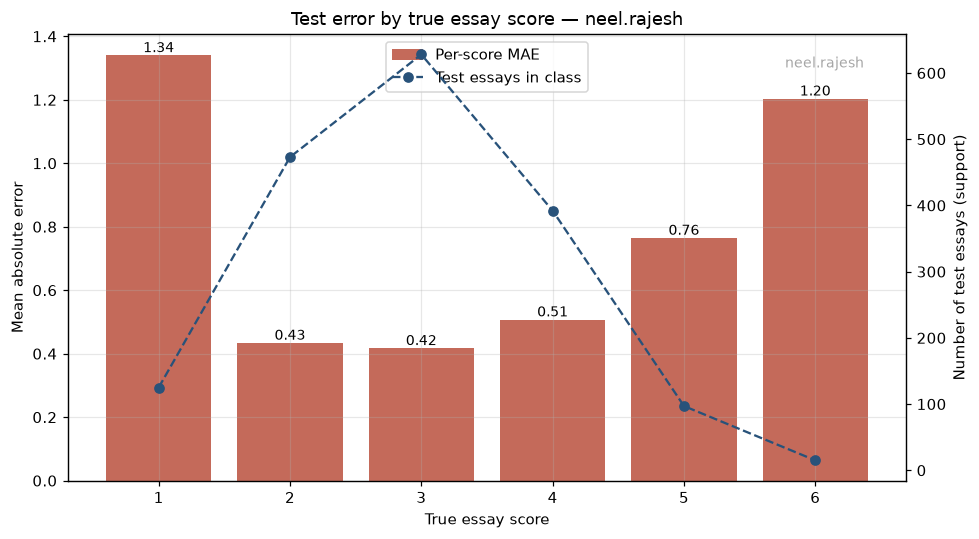

In [29]:
results_viz.plot_error_profile(y_test, y_test_pred, SCORE_LABELS)

In [30]:
# Baselines for context: a metric is only meaningful relative to what trivial
# strategies achieve on the same imbalanced data.
majority_class = float(pd.Series(y_train).mode().iloc[0])
baseline_majority = np.full(len(y_test), majority_class)
baseline_mean = np.full(len(y_test), float(np.mean(y_train)))

baselines = pd.DataFrame({
    f"Always predict {majority_class:.0f} (majority class)":
        ScoringMetrics.evaluate(y_test, baseline_majority),
    f"Always predict {np.mean(y_train):.2f} (training mean)":
        ScoringMetrics.evaluate(y_test, baseline_mean),
    f"KNN regression (k={BEST_K}, {BEST_METRIC})":
        test_metrics,
}).T.round(4)
baselines

,MAE,RMSE,R2,Pearson_r,Accuracy,Within_1
Always predict 3 (majority class),0.7827,1.0447,-0.0026,NaN,0.3630,0.8630
Always predict 2.95 (training mean),0.7986,1.0433,-0.0000,NaN,0.3630,0.6364
"KNN regression (k=21, euclidean)",0.5349,0.7050,0.5434,0.7386,0.5618,0.8653


In [31]:

# Does the regression form (averaging) actually beat the classification form
# (majority vote) on this data? Both are computed from the SAME neighbour sets,
# so the comparison isolates the aggregation rule alone.
_, test_neighbour_labels = final_model.kneighbors(X_test_std, k=BEST_K)

pred_average = test_neighbour_labels.mean(axis=1)              # regression form

classes = np.unique(y_train)
one_hot = test_neighbour_labels[:, :, None] == classes[None, None, :]
votes = one_hot.sum(axis=1)
pred_vote = classes[votes.argmax(axis=1)]                      # classification form
                                                               # (ties -> lowest grade)

aggregation_comparison = pd.DataFrame({
    "Majority vote (classification)": ScoringMetrics.evaluate(y_test, pred_vote),
    "Mean of neighbours (regression)": ScoringMetrics.evaluate(y_test, pred_average),
}).T.round(4)
aggregation_comparison


,MAE,RMSE,R2,Pearson_r,Accuracy,Within_1
Majority vote (classification),0.4948,0.782,0.4382,0.6848,0.5566,0.9549
Mean of neighbours (regression),0.5349,0.705,0.5434,0.7386,0.5618,0.8653



### Discussion of the test results

#### Headline numbers

| Metric | Test value | Reading |
|---|---|---|
| **MAE** | **0.5349** | The average prediction is about half a grade from the truth. |
| **RMSE** | **0.7050** | Larger than MAE, so errors are not uniform — a minority are badly wrong. |
| **$R^2$** | **0.5434** | The 17 handcrafted features explain ~54% of the variance in human scores. |
| **Pearson $r$** | **0.7386** | Strong linear association between predicted and true scores. |
| Exact match (rounded) | 0.5618 | 56% land on exactly the right grade after rounding. |
| Within one grade | 0.8653 | 87% are within one grade. |

Validation gave MAE 0.5353, RMSE 0.6912, $R^2$ 0.5630, $r$ 0.7508 — test is within about
0.02 on every metric, so selecting a configuration over 24 candidates did not overfit the
validation split.

#### The model is genuinely learning

| Strategy | MAE | RMSE | $R^2$ | Pearson $r$ |
|---|---|---|---|---|
| Always predict 3 (majority class) | 0.7827 | 1.0447 | −0.003 | undefined |
| Always predict 2.95 (training mean) | 0.7986 | 1.0433 | 0.0000 | undefined |
| **KNN regression (K=21, Euclidean)** | **0.5349** | **0.7050** | **0.5434** | **0.7386** |

A 32% MAE reduction over the majority-class baseline. Pearson $r$ is undefined for both
baselines because a constant prediction has zero variance — which is itself the point:
those baselines carry no information about *which* essay is better, while $r = 0.739$ says
the model ranks essays well.

#### Averaging versus majority voting

The comparison cell above runs both aggregation rules over the identical neighbour sets, so
the difference is attributable to the rule alone:

| | MAE | RMSE | $R^2$ | Pearson $r$ |
|---|---|---|---|---|
| Majority vote | **0.4948** | 0.7820 | 0.4382 | 0.6848 |
| Mean of neighbours | 0.5349 | **0.7050** | **0.5434** | **0.7386** |

Averaging is worse on MAE but better on the other three, and substantially so:
$R^2$ rises by 0.105 and RMSE falls by 0.077.

The mechanism is straightforward. Majority voting always outputs an integer, so when it is
right it is exactly right — which flatters MAE. But when it is wrong it is wrong by a whole
grade or more, and RMSE punishes that quadratically. Averaging hedges: it answers 3.4
rather than committing to 3 or 4, accepting a small error on nearly every essay in exchange
for far fewer large ones, and preserving the ordinal information that lifts $R^2$ and $r$.

This is a concrete demonstration of why selecting on a single metric is unsafe. Judged on
MAE alone, the classifier looks better and the regressor would have been rejected — while
$R^2$, RMSE and $r$ all say the opposite, and the regression form is what the four
assignment metrics are designed to measure.

#### Where the errors are

| Score | True essays | Predicted as this | Correctly recovered |
|---|---|---|---|
| 1 | 125 | 3 | **2 (1.6%)** |
| 2 | 473 | 518 | 316 (66.8%) |
| 3 | 628 | 760 | 414 (65.9%) |
| 4 | 392 | 382 | 209 (53.3%) |
| 5 | 97 | 67 | 31 (32.0%) |
| 6 | 15 | **0** | **0 (0%)** |

The continuous predictions span only **[1.381, 5.381]**. Grade 6 is therefore literally
unreachable after rounding — no test essay is ever assigned a 6 — and grade 1 is nearly so.

This is inherent to averaging under class imbalance, not a bug. A prediction is the mean of
21 neighbours; to output 6 all 21 would have to be 6s, but score-6 essays are 0.9% of the
training set, so no such neighbourhood exists anywhere in the feature space. Regression
shrinks predictions toward the conditional mean, and the conditional mean of a
neighbourhood is never extreme when the extremes are rare.

Note the trade-off against the classification form: averaging improved every aggregate
metric except MAE, but made the extreme classes *worse*: majority voting can at least return a 6 when a
neighbourhood happens to contain enough of them, whereas an average of 21 neighbours
mathematically cannot. Aggregate accuracy and extreme-class coverage pull in opposite
directions here.

#### Limitations and possible improvements

1. **Class imbalance is the dominant limitation.** Distance-weighted averaging, class
   rebalancing, or resampling would trade aggregate accuracy for usable predictions at the
   extremes.
2. **Feature redundancy** (1.2 c): five near-collinear volume features give "length"
   roughly five times the weight of any single style feature under Z-scoring. PCA, or
   pruning the redundant band counts, would rebalance this.
3. **Every feature is weighted equally** by Z-scoring regardless of how informative it is.
   Feature weights learned on the validation set would let the strong features dominate.
4. **The K grid should be extended** past 21, although the curve is close to flat by then.
5. **Only surface statistics are measured.** Nothing here captures argument structure,
   topical relevance or factual content — a ceiling on what handcrafted counting features
   can achieve, and the reason $R^2$ settles near 0.54.
